# Part 7: 금리와 옵션가격을 이용한 내재변동성(Implied Volatility) 직접 계산

**1**. **잔존만기(Time to maturity, TTM) 계산**

In [ ]:
import pandas as pd
from google.colab import files

# 1. 데이터셋 파일명: KOSPI200_final_liquid_filtered.csv 로드
try:
    df_ttm = pd.read_csv('/content/KOSPI200_final_liquid_filtered.csv')
    print("'KOSPI200_final_liquid_filtered.csv' 파일을 성공적으로 로드했습니다.")
except FileNotFoundError:
    print("'KOSPI200_final_liquid_filtered.csv' 파일을 찾을 수 없습니다. 경로를 확인해주세요.")
    # 파일이 없을 경우 빈 DataFrame으로 초기화하여 다음 작업에서 오류 방지
    df_ttm = pd.DataFrame()

if not df_ttm.empty:
    # 2. 날짜 전처리: '일자_datetime' 컬럼과 'Final_LTD'(최종거래일) 컬럼을 datetime 형식으로 변환
    if '일자_datetime' in df_ttm.columns and 'Final_LTD' in df_ttm.columns:
        df_ttm['일자_datetime'] = pd.to_datetime(df_ttm['일자_datetime'])
        df_ttm['Final_LTD'] = pd.to_datetime(df_ttm['Final_LTD'])
        print("날짜 컬럼 ('일자_datetime', 'Final_LTD')을 datetime 형식으로 변환했습니다.")

        # 3. TTM 계산 공식 적용 및 4. 컬럼 추가: 'TTM_years' 컬럼 생성
        # TTM = (Final_LTD - 일자_datetime) / 365.25
        df_ttm['TTM_years'] = (df_ttm['Final_LTD'] - df_ttm['일자_datetime']).dt.days / 365.25
        print("'TTM_years' 컬럼을 성공적으로 계산하여 추가했습니다.")

        # 5. 검증: 상위 5개 행(head) 출력
        print("\n'일자_datetime', 'Final_LTD', 'TTM_years' 컬럼 검증 (상위 5개 행):")
        display(df_ttm[['일자_datetime', 'Final_LTD', 'TTM_years']].head())

        # 6. 모든 작업 완료 후 TTM_years 컬럼이 포함된 새로운 CSV 파일로 저장 및 다운로드 링크 제공
        output_filename = 'KOSPI200_final_liquid_filtered_with_TTM.csv'
        df_ttm.to_csv(output_filename, index=False)
        print(f"\n'{output_filename}' 파일로 저장되었습니다. 다운로드 링크를 제공합니다:")
        files.download(output_filename)
    else:
        print("필수 날짜 컬럼 ('일자_datetime' 또는 'Final_LTD')이 데이터프레임에 없습니다. 컬럼 이름을 확인해주세요.")
else:
    print("데이터프레임이 비어 있어 TTM 계산을 수행할 수 없습니다.")

'KOSPI200_final_liquid_filtered.csv' 파일을 성공적으로 로드했습니다.
날짜 컬럼 ('일자_datetime', 'Final_LTD')을 datetime 형식으로 변환했습니다.
'TTM_years' 컬럼을 성공적으로 계산하여 추가했습니다.

'일자_datetime', 'Final_LTD', 'TTM_years' 컬럼 검증 (상위 5개 행):


,일자_datetime,Final_LTD,TTM_years
0,2002-12-30,2003-01-09,0.027379
1,2002-12-30,2003-01-09,0.027379
2,2002-12-30,2003-01-09,0.027379
3,2002-12-30,2003-01-09,0.027379
4,2002-12-30,2003-01-09,0.027379



'KOSPI200_final_liquid_filtered_with_TTM.csv' 파일로 저장되었습니다. 다운로드 링크를 제공합니다:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

코드 설명

---

1.  **파일 로드 (`pd.read_csv('/content/KOSPI200_final_liquid_filtered.csv')`):**
    *   `KOSPI200_final_liquid_filtered.csv` 파일을 읽어 `df_ttm`이라는 pandas DataFrame으로 저장합니다.
    *   `try-except` 블록을 사용하여 파일이 존재하지 않을 경우 `FileNotFoundError`를 처리하고 사용자에게 알립니다.

2.  **날짜 전처리 (`df_ttm['일자_datetime'] = pd.to_datetime(...)` 등):**
    *   데이터프레임이 비어 있지 않은 경우에만 다음 작업을 진행합니다.
    *   `일자_datetime`과 `Final_LTD` 컬럼이 데이터프레임에 있는지 확인합니다.
    *   `pd.to_datetime()` 함수를 사용하여 해당 컬럼들의 데이터를 날짜 및 시간(datetime) 형식으로 변환합니다. 이는 날짜 계산을 가능하게 합니다.

3.  **TTM 계산 및 컬럼 추가 (`df_ttm['TTM_years'] = (df_ttm['Final_LTD'] - df_ttm['일자_datetime']).dt.days / 365.25`):**
    *   `Final_LTD`(최종거래일)에서 `일자_datetime`(현재 일자)을 빼서 두 날짜 간의 일수 차이를 계산합니다 (`.dt.days`).
    *   이 일수 차이를 `365.25`로 나누어 연 단위의 잔존만기(`TTM_years`)를 계산합니다. `365.25`를 사용하는 것은 윤년을 고려하고 기존 데이터와의 정합성을 맞추기 위함입니다.
    *   계산된 `TTM_years` 값을 데이터프레임에 새로운 컬럼으로 추가합니다.

4.  **계산 검증 (`display(df_ttm[['일자_datetime', 'Final_LTD', 'TTM_years']].head())`):**
    *   계산이 올바르게 이루어졌는지 확인하기 위해 `일자_datetime`, `Final_LTD`, `TTM_years` 컬럼의 상위 5개 행을 출력합니다.

5.  **파일 저장 및 다운로드 링크 제공 (`df_ttm.to_csv(...)`, `files.download(...)`):**
    *   `TTM_years` 컬럼이 추가된 `df_ttm` DataFrame을 `KOSPI200_final_liquid_filtered_with_TTM.csv`라는 이름의 새로운 CSV 파일로 저장합니다. `index=False`는 데이터프레임 인덱스가 파일에 저장되지 않도록 합니다.
    *   `google.colab.files.download()` 함수를 사용하여 사용자에게 저장된 파일을 다운로드할 수 있는 링크를 제공합니다.

**2. 수치해법을 이용한 콜옵션의 내재변동성 추정**

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm

# 1. 블랙숄츠 콜 옵션 이론가 계산 함수
def bs_call_price(S, K, r, q, T, sigma):
    if T <= 0 or sigma <= 0:
        return 0.0 # Or raise ValueError, depending on desired strictness

    if S <= 0 or K <= 0: # Ensure underlying and strike are positive
        return 0.0

    try:
        d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)

        call_price = S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
        return call_price
    except Exception: # Catch potential numerical errors (e.g., log of non-positive)
        return np.nan

# 3. 데이터 로드 및 계산 적용
file_path = 'KOSPI200_final_liquid_filtered_with_TTM.csv'
try:
    df = pd.read_csv(file_path)
    print(f"'{file_path}' 파일을 성공적으로 로드했습니다.")
except FileNotFoundError:
    print("지정한 경로에 파일이 없습니다. 예시 데이터로 대체 실행합니다.")
    df = pd.DataFrame({
        'S_t': [360.5, 360.5],
        'K': [360.0, 362.5],
        'rf': [3.5, 3.5],  # 3.5%
        'q': [0.015, 0.015],  # 1.5%
        'TTM_years': [0.084, 0.084],  # 잔존만기 (년 단위 예: 30일/365일)
        '종가': [5.20, 3.80],
        '옵션 종류': ['Call', 'Call'] # Changed to 'Call' for consistency
    })

if not df.empty:
    print(f"로드된 데이터프레임 컬럼: {df.columns.tolist()}")

    # Filter for Call options only before mapping, as bs_call_price is for calls
    if '옵션 종류' in df.columns:
        unique_option_types = df['옵션 종류'].unique().tolist()
        print(f"분석 전 '옵션 종류' 컬럼의 고유 값: {unique_option_types}")

        # Filter for 'Call' (case-insensitive for robustness)
        df_calls = df[df['옵션 종류'].astype(str).str.contains('Call', case=False, na=False)].copy()
        if df_calls.empty:
            print(f"경고: '옵션 종류' 컬럼에 'Call'이(가) 없어 콜옵션 필터링 결과가 비었습니다. 고유 값을 확인하고 정확한 콜옵션 문자열을 사용해주세요.")
            df = df_calls # df becomes empty if no 'Call'
        else:
            df = df_calls
            print(f"'Call'로 필터링 후 {len(df)}개 행이 남았습니다.")
    else:
        print("경고: '옵션 종류' 컬럼이 없어 콜옵션 필터링을 수행할 수 없습니다. 모든 옵션 타입에 대해 계산을 시도합니다 (주의: 블랙숄츠는 콜옵션 전용).")

    # 맵핑 전 필요한 컬럼이 있는지 확인 (사용자에게 어떤 컬럼이 사용될지 명확히 함)
    expected_source_cols = ['S_t', 'K', 'rf', 'TTM_years', '종가']
    for col in expected_source_cols:
        if col not in df.columns:
            print(f"경고: 필요한 소스 컬럼 '{col}'이(가) 데이터프레임에 없습니다. 해당 컬럼은 NaN으로 처리됩니다.")

    # S ($S$: 기초자산 가격): 'S_t' 컬럼 사용
    df['S'] = df['S_t'] if 'S_t' in df.columns else np.nan

    # K ($K$: 행사가격): 'K' 컬럼 사용
    df['K'] = df['K'] if 'K' in df.columns else np.nan

    # r ($r$: 무위험 이자율): 'rf' 컬럼 사용 및 100으로 나누기
    df['r'] = df['rf'] / 100.0 if 'rf' in df.columns else np.nan # Fallback to np.nan if 'rf' is missing
    if 'rf' in df.columns: print("확인: 'rf' 컬럼의 값을 100으로 나누어 'r' (무위험 이자율)로 설정했습니다.")

    # q ($q$: 배당수익률): 'q' 또는 '배당수익률' 컬럼 사용, 없으면 0.0 사용
    if 'q' in df.columns:
        df['q'] = df['q']
    elif '배당수익률' in df.columns:
        df['q'] = df['배당수익률']
    else:
        print(f"경고: 'q' 또는 '배당수익률' 컬럼이 없어 기본값 0.0을 사용합니다.")
        df['q'] = 0.0

    # T ($T$: 잔존만기): 'TTM_years' 컬럼 사용
    df['T'] = df['TTM_years'] if 'TTM_years' in df.columns else np.nan

    # C_mkt ($C^{mkt}$: 실제 체결된 콜 옵션의 시장 가격): '종가' 컬럼 사용
    df['C_mkt'] = df['종가'] if '종가' in df.columns else np.nan

    print("데이터 컬럼을 블랙숄츠 모델에 맞게 조정했습니다.")

    # NaN 값 처리
    initial_rows = len(df)
    df.dropna(subset=['T', 'C_mkt'], inplace=True)
    rows_after_dropping = len(df)
    print(f"'T' 또는 'C_mkt' 컬럼에 NaN 값이 있는 {initial_rows - rows_after_dropping}개 행을 제거했습니다.")

    print("\n조정된 데이터프레임의 상위 10개 행 (필요 컬럼):")
    display(df[['S', 'K', 'T', 'C_mkt', 'r', 'q']].head(10))
    print(f"필수 컬럼에 NaN 값 개수:\n{df[['S', 'K', 'T', 'C_mkt', 'r', 'q']].isnull().sum()}")

else:
    print("데이터프레임이 비어 있어 계산을 수행할 수 없습니다.")

'KOSPI200_final_liquid_filtered_with_TTM.csv' 파일을 성공적으로 로드했습니다.
로드된 데이터프레임 컬럼: ['일자', '종목코드', '종목명', '종가', '대비', '시가', '고가', '저가', '내재변동성', '익일기준가', '거래량', '거래대금', '미결제약정', '결제월', 'Calculated_LTD', 'Final_LTD', '일자_datetime', 'M_t', 'm_t_near', 'S_t', 'rf', 'K', '옵션 종류', 'Moneyness (M)', '상태 분류', 'TTM_years']
분석 전 '옵션 종류' 컬럼의 고유 값: [nan, 'Call', 'Put']
'Call'로 필터링 후 221944개 행이 남았습니다.
확인: 'rf' 컬럼의 값을 100으로 나누어 'r' (무위험 이자율)로 설정했습니다.
경고: 'q' 또는 '배당수익률' 컬럼이 없어 기본값 0.0을 사용합니다.
데이터 컬럼을 블랙숄츠 모델에 맞게 조정했습니다.
'T' 또는 'C_mkt' 컬럼에 NaN 값이 있는 78792개 행을 제거했습니다.

조정된 데이터프레임의 상위 10개 행 (필요 컬럼):


,S,K,T,C_mkt,r,q
16097,263.92,227.5,0.035592,36.35,0.0289,0.0
16098,263.92,230.0,0.035592,34.50,0.0289,0.0
16099,263.92,232.5,0.035592,32.00,0.0289,0.0
16100,263.92,235.0,0.035592,29.55,0.0289,0.0
16101,263.92,237.5,0.035592,27.25,0.0289,0.0
16102,263.92,240.0,0.035592,24.75,0.0289,0.0
16103,263.92,242.5,0.035592,22.25,0.0289,0.0
16104,263.92,245.0,0.035592,19.90,0.0289,0.0
16105,263.92,247.5,0.035592,17.00,0.0289,0.0
16106,263.92,250.0,0.035592,15.05,0.0289,0.0


필수 컬럼에 NaN 값 개수:
S        0
K        0
T        0
C_mkt    0
r        0
q        0
dtype: int64


In [ ]:
from scipy.optimize import brentq # brentq 함수를 임포트

# 2. 수치해법(Brent 방법)을 이용한 내재변동성(IV) 산출 함수
def calculate_implied_volatility(S, K, r, q, T, C_mkt):
    # 목적함수 f(σ) = BS_Price(σ) - Mkt_Price
    def objective_function(sigma):
        return bs_call_price(S, K, r, q, T, sigma) - C_mkt

    # 옵션 가격의 이론적 하한선 및 상한선 체크 (오류 방지)
    # Call option theoretical lower bound: S*e^(-qT) - K*e^(-rT)
    min_call_intrinsic = max(0.0, S * np.exp(-q * T) - K * np.exp(-r * T))
    # Call option theoretical upper bound: S*e^(-qT)
    max_call_theoretical = S * np.exp(-q * T)

    # 시장 가격이 이론적 범위를 벗어나면 IV 계산 불가능
    if C_mkt <= min_call_intrinsic or C_mkt >= max_call_theoretical:
        return np.nan  # 차익거래 기회가 존재하거나 수렴 불가능한 가격일 때 무시

    try:
        # 변동성 탐색 범위 설정: 0.01% (1e-4) ~ 500% (5.0)
        # brentq는 f(a)와 f(b)의 부호가 달라야 함. 즉, IV가 이 범위 안에 있어야 함.
        # 만약 objective_function(1e-4) > 0 이고 objective_function(5.0) < 0 이면 범위가 적절치 않을 수 있음.
        # 이 경우, 초기 추정치 또는 범위 조정을 고려해야 함.

        # 블랙숄츠 가격이 시장 가격보다 낮을 때 sigma를 올려야 하므로, objective_function은 sigma에 대해 증가 함수여야 함.
        # 일반적으로 0.01% ~ 500% 범위에서 내재변동성을 찾음.
        implied_vol = brentq(objective_function, 1e-4, 5.0)
        return implied_vol
    except ValueError:
        # 수렴에 실패한 경우 (예: 초기 범위 내에 해가 없거나, 부호가 일치하는 경우)
        return np.nan


# Black-Scholes 이론가 계산
# df['BS_Price'] = df.apply(lambda row: bs_call_price(row['S'], row['K'], row['r'], row['q'], row['T'], row['sigma_mkt']), axis=1)
# 위의 주석 처리된 코드는 'sigma_mkt'라는 변동성 컬럼이 있을 때 사용. 지금은 단순히 IV 계산을 위한 초기 단계이므로 IV는 직접 계산.

# df['BS_Price'] 컬럼 생성 (임시로, IV 계산 후에는 필요하면 특정 sigma로 계산 가능)
# 여기서는 단순히 계산 과정을 보여주기 위함이며, 실제 시그마는 IV를 통해 찾아야 함.
# 일단 IV를 0.2 (20%)로 가정하고 이론가를 계산해봅시다.
print("블랙숄츠 이론가 (임시 변동성 20% 가정)를 계산합니다.")
df['BS_Price_temp_sigma'] = df.apply(lambda row: bs_call_price(row['S'], row['K'], row['r'], row['q'], row['T'], 0.2), axis=1)


# 내재변동성 계산 적용
print("내재변동성을 계산합니다. 이 과정은 시간이 걸릴 수 있습니다...")
df['Implied_Volatility'] = df.apply(lambda row: calculate_implied_volatility(
    row['S'], row['K'], row['r'], row['q'], row['T'], row['C_mkt']), axis=1)

print("\n이론가 및 내재변동성 계산 완료. 상위 10개 행 (결과 컬럼 포함):")
display(df[['S', 'K', 'T', 'C_mkt', 'r', 'q', 'BS_Price_temp_sigma', 'Implied_Volatility']].head(10))

print(f"\n내재변동성 계산 후 NaN 값 개수: {df['Implied_Volatility'].isnull().sum()}")

블랙숄츠 이론가 (임시 변동성 20% 가정)를 계산합니다.
내재변동성을 계산합니다. 이 과정은 시간이 걸릴 수 있습니다...

이론가 및 내재변동성 계산 완료. 상위 10개 행 (결과 컬럼 포함):


,S,K,T,C_mkt,r,q,BS_Price_temp_sigma,Implied_Volatility
16097,263.92,227.5,0.035592,36.35,0.0289,0.0,36.653966,NaN
16098,263.92,230.0,0.035592,34.50,0.0289,0.0,34.156728,0.426685
16099,263.92,232.5,0.035592,32.00,0.0289,0.0,31.659881,0.398615
16100,263.92,235.0,0.035592,29.55,0.0289,0.0,29.164080,0.381069
16101,263.92,237.5,0.035592,27.25,0.0289,0.0,26.670825,0.386742
16102,263.92,240.0,0.035592,24.75,0.0289,0.0,24.183257,0.356540
16103,263.92,242.5,0.035592,22.25,0.0289,0.0,21.707368,0.326249
16104,263.92,245.0,0.035592,19.90,0.0289,0.0,19.253564,0.314320
16105,263.92,247.5,0.035592,17.00,0.0289,0.0,16.838335,0.230606
16106,263.92,250.0,0.035592,15.05,0.0289,0.0,14.485471,0.265003



내재변동성 계산 후 NaN 값 개수: 28752


In [ ]:
from google.colab import files

output_csv_filename = 'calculated_options_data.csv'
df.to_csv(output_csv_filename, index=False, encoding='utf-8-sig')
print(f"'{output_csv_filename}' 파일로 저장되었습니다.")
files.download(output_csv_filename)
print("CSV 파일 다운로드 링크가 제공되었습니다.")

'calculated_options_data.csv' 파일로 저장되었습니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

CSV 파일 다운로드 링크가 제공되었습니다.


In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

# 데이터프레임의 상위 일부만 선택
df_to_save_image = df[['S', 'K', 'T', 'C_mkt', 'r', 'q', 'BS_Price_temp_sigma', 'Implied_Volatility']].head(10)

# DataFrame을 Matplotlib 테이블로 렌더링하고 이미지로 저장
output_png_filename = 'calculated_options_data_head.png'

fig, ax = plt.subplots(figsize=(16, 6)) # 이미지 크기 조정 (더 넓게)
ax.axis('off') # 축 숨기기

# 테이블 스타일링
table = ax.table(cellText=df_to_save_image.values,
                 colLabels=df_to_save_image.columns,
                 loc='center',
                 cellLoc='center', # 셀 내용 중앙 정렬
                 colLoc='center') # 컬럼 헤더 중앙 정렬

table.auto_set_font_size(False)
table.set_fontsize(10) # 폰트 크기 조정
table.scale(1.2, 1.2) # 테이블 크기 스케일 조정 (폰트 및 셀 크기)

# 헤더 스타일링
for (i, j), cell in table.get_celld().items():
    if i == 0: # 헤더 행
        cell.set_facecolor("#ADD8E6") # 밝은 파란색 배경
        cell.set_text_props(weight='bold', color='black') # 굵은 글씨, 검정색
    else:
        cell.set_facecolor("white") # 데이터 셀 배경색
        cell.set_edgecolor("black") # 셀 경계선 색상

plt.title('Calculated Options Data Head (Top 10 Rows)', fontsize=14, loc='center', pad=20) # 제목 스타일링
plt.savefig(output_png_filename, bbox_inches='tight', dpi=300)
plt.close(fig) # 메모리 절약을 위해 그림 닫기

print(f"'{output_png_filename}' 파일로 저장되었습니다.")
files.download(output_png_filename)
print("PNG 이미지 파일 다운로드 링크가 제공되었습니다.")

'calculated_options_data_head.png' 파일로 저장되었습니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PNG 이미지 파일 다운로드 링크가 제공되었습니다.


**3. 수치해법을 이용한 풋옵션의 내재변동성 추정**

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm

# 1. 블랙숄츠 풋 옵션 이론가 계산 함수
def bs_put_price(S, K, r, q, T, sigma):
    if T <= 0 or sigma <= 0:
        return 0.0

    if S <= 0 or K <= 0:
        return 0.0

    try:
        d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)

        # 이미지의 풋 옵션 수식 적용
        put_price = K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)
        return put_price
    except Exception:
        return np.nan

# 3. 데이터 로드 및 계산 적용
file_path = 'KOSPI200_final_liquid_filtered_with_TTM.csv'
try:
    df = pd.read_csv(file_path)
    print(f"'{file_path}' 파일을 성공적으로 로드했습니다.")
except FileNotFoundError:
    print("지정한 경로에 파일이 없습니다. 예시 데이터로 대체 실행합니다.")
    df = pd.DataFrame({
        'S_t': [360.5, 360.5],
        'K': [360.0, 362.5],
        'rf': [3.5, 3.5],  # 3.5%
        'q': [0.015, 0.015],  # 1.5%
        'TTM_years': [0.084, 0.084],  # 잔존만기
        '종가': [4.20, 5.80],
        '옵션 종류': ['Put', 'Put']  # 'Put'으로 변경
    })

if not df.empty:
    print(f"로드된 데이터프레임 컬럼: {df.columns.tolist()}")

    # 풋 옵션 데이터만 필터링
    if '옵션 종류' in df.columns:
        unique_option_types = df['옵션 종류'].unique().tolist()
        print(f"분석 전 '옵션 종류' 컬럼의 고유 값: {unique_option_types}")

        # 대소문자 구분 없이 'Put' 포함 여부 확인
        df_puts = df[df['옵션 종류'].astype(str).str.contains('Put', case=False, na=False)].copy()
        if df_puts.empty:
            print(f"경고: '옵션 종류' 컬럼에 'Put'이(가) 없어 풋옵션 필터링 결과가 비었습니다. 고유 값을 확인해주세요.")
            df = df_puts
        else:
            df = df_puts
            print(f"'Put'으로 필터링 후 {len(df)}개 행이 남았습니다.")
    else:
        print("경고: '옵션 종류' 컬럼이 없어 풋옵션 필터링을 수행할 수 없습니다. 모든 데이터에 대해 계산을 시도합니다.")

    # 필요한 소스 컬럼 존재 여부 확인
    expected_source_cols = ['S_t', 'K', 'rf', 'TTM_years', '종가']
    for col in expected_source_cols:
        if col not in df.columns:
            print(f"경고: 필요한 소스 컬럼 '{col}'이(가) 데이터프레임에 없습니다. 해당 컬럼은 NaN으로 처리됩니다.")

    # 변수 매핑
    df['S'] = df['S_t'] if 'S_t' in df.columns else np.nan
    df['K'] = df['K'] if 'K' in df.columns else np.nan

    # 무위험이자율 변환 (백분율 -> 소수점)
    df['r'] = df['rf'] / 100.0 if 'rf' in df.columns else np.nan
    if 'rf' in df.columns:
        print("확인: 'rf' 컬럼의 값을 100으로 나누어 'r' (무위험 이자율)로 설정했습니다.")

    # 배당수익률 설정
    if 'q' in df.columns:
        df['q'] = df['q']
    elif '배당수익률' in df.columns:
        df['q'] = df['배당수익률']
    else:
        print(f"경고: 'q' 또는 '배당수익률' 컬럼이 없어 기본값 0.0을 사용합니다.")
        df['q'] = 0.0

    df['T'] = df['TTM_years'] if 'TTM_years' in df.columns else np.nan

    # 풋 옵션 시장 가격 설정
    df['P_mkt'] = df['종가'] if '종가' in df.columns else np.nan

    print("데이터 컬럼을 블랙숄츠 모델에 맞게 조정했습니다.")

    # 결측치 처리
    initial_rows = len(df)
    df.dropna(subset=['T', 'P_mkt'], inplace=True)
    rows_after_dropping = len(df)
    print(f"'T' 또는 'P_mkt' 컬럼에 NaN 값이 있는 {initial_rows - rows_after_dropping}개 행을 제거했습니다.")

    print("\n조정된 데이터프레임의 상위 10개 행 (필요 컬럼):")
    display(df[['S', 'K', 'T', 'P_mkt', 'r', 'q']].head(10))
    print(f"필수 컬럼에 NaN 값 개수:\n{df[['S', 'K', 'T', 'P_mkt', 'r', 'q']].isnull().sum()}")

else:
    print("데이터프레임이 비어 있어 계산을 수행할 수 없습니다.")

'KOSPI200_final_liquid_filtered_with_TTM.csv' 파일을 성공적으로 로드했습니다.
로드된 데이터프레임 컬럼: ['일자', '종목코드', '종목명', '종가', '대비', '시가', '고가', '저가', '내재변동성', '익일기준가', '거래량', '거래대금', '미결제약정', '결제월', 'Calculated_LTD', 'Final_LTD', '일자_datetime', 'M_t', 'm_t_near', 'S_t', 'rf', 'K', '옵션 종류', 'Moneyness (M)', '상태 분류', 'TTM_years']
분석 전 '옵션 종류' 컬럼의 고유 값: [nan, 'Call', 'Put']
'Put'으로 필터링 후 233198개 행이 남았습니다.
확인: 'rf' 컬럼의 값을 100으로 나누어 'r' (무위험 이자율)로 설정했습니다.
경고: 'q' 또는 '배당수익률' 컬럼이 없어 기본값 0.0을 사용합니다.
데이터 컬럼을 블랙숄츠 모델에 맞게 조정했습니다.
'T' 또는 'P_mkt' 컬럼에 NaN 값이 있는 61519개 행을 제거했습니다.

조정된 데이터프레임의 상위 10개 행 (필요 컬럼):


,S,K,T,P_mkt,r,q
16119,263.92,227.5,0.035592,0.05,0.0289,0.0
16120,263.92,230.0,0.035592,0.06,0.0289,0.0
16121,263.92,232.5,0.035592,0.07,0.0289,0.0
16122,263.92,235.0,0.035592,0.09,0.0289,0.0
16123,263.92,237.5,0.035592,0.10,0.0289,0.0
16124,263.92,240.0,0.035592,0.13,0.0289,0.0
16125,263.92,242.5,0.035592,0.14,0.0289,0.0
16126,263.92,245.0,0.035592,0.17,0.0289,0.0
16127,263.92,247.5,0.035592,0.23,0.0289,0.0
16128,263.92,250.0,0.035592,0.30,0.0289,0.0


필수 컬럼에 NaN 값 개수:
S        0
K        0
T        0
P_mkt    0
r        0
q        0
dtype: int64


In [ ]:
import numpy as np
from scipy.optimize import brentq
from scipy.stats import norm

# 1. 배당을 고려한 Black-Scholes Put 옵션 이론가 계산 함수
def bs_put_price(S, K, r, q, T, sigma):
    # 만기가 0 이하이거나 변동성이 0 이하인 경우 극단적 상황 처리
    if T <= 0 or sigma <= 0:
        return max(0.0, K * np.exp(-r * T) - S * np.exp(-q * T))

    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    # 이미지 수식: P = K * e^(-rT) * N(-d2) - S * e^(-qT) * N(-d1)
    put_price = K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)
    return put_price

# 2. 수치해법(Brent 방법)을 이용한 Put 옵션 내재변동성(IV) 산출 함수
def calculate_put_implied_volatility(S, K, r, q, T, P_mkt):
    # 목적함수 f(σ) = BS_Put_Price(σ) - Mkt_Price
    def objective_function(sigma):
        return bs_put_price(S, K, r, q, T, sigma) - P_mkt

    # Put 옵션의 이론적 하한선 및 상한선 체크 (오류 방지)
    # Put option theoretical lower bound: K*e^(-rT) - S*e^(-qT)
    min_put_intrinsic = max(0.0, K * np.exp(-r * T) - S * np.exp(-q * T))
    # Put option theoretical upper bound: K*e^(-rT)
    max_put_theoretical = K * np.exp(-r * T)

    # 시장 가격이 이론적 범위를 벗어나면 IV 계산 불가능 (차익거래 기회 또는 데이터 오류)
    if P_mkt <= min_put_intrinsic or P_mkt >= max_put_theoretical:
        return np.nan

    try:
        # 변동성 탐색 범위 설정: 0.01% (1e-4) ~ 500% (5.0)
        #  Vega는 항상 양수이므로, Put 가격도 sigma에 대해 증가함수입니다. brentq 적용 가능.
        implied_vol = brentq(objective_function, 1e-4, 5.0)
        return implied_vol
    except ValueError:
        # 수렴에 실패한 경우 (예: 초기 범위 내에 해가 없는 경우)
        return np.nan


# 3. 데이터프레임 적용 및 출력 부분

# Put 옵션 블랙숄츠 이론가 (임시 변동성 20% 가정) 계산
print("블랙숄츠 Put 이론가 (임시 변동성 20% 가정)를 계산합니다.")
df['BS_Price_temp_sigma'] = df.apply(lambda row: bs_put_price(row['S'], row['K'], row['r'], row['q'], row['T'], 0.2), axis=1)

# Put 옵션 내재변동성 계산 적용 (C_mkt 대신 P_mkt 사용)
print("Put 옵션 내재변동성을 계산합니다. 이 과정은 시간이 걸릴 수 있습니다...")
df['Implied_Volatility'] = df.apply(lambda row: calculate_put_implied_volatility(
    row['S'], row['K'], row['r'], row['q'], row['T'], row['P_mkt']), axis=1)

print("\n이론가 및 내재변동성 계산 완료. 상위 10개 행 (결과 컬럼 포함):")
# 데이터프레임에 Put 시장가 컬럼명이 'P_mkt'로 되어 있다고 가정합니다.
display(df[['S', 'K', 'T', 'P_mkt', 'r', 'q', 'BS_Price_temp_sigma', 'Implied_Volatility']].head(10))

print(f"\n내재변동성 계산 후 NaN 값 개수: {df['Implied_Volatility'].isnull().sum()}")

블랙숄츠 Put 이론가 (임시 변동성 20% 가정)를 계산합니다.
Put 옵션 내재변동성을 계산합니다. 이 과정은 시간이 걸릴 수 있습니다...

이론가 및 내재변동성 계산 완료. 상위 10개 행 (결과 컬럼 포함):


,S,K,T,P_mkt,r,q,BS_Price_temp_sigma,Implied_Volatility
16119,263.92,227.5,0.035592,0.05,0.0289,0.0,0.000078,0.337934
16120,263.92,230.0,0.035592,0.06,0.0289,0.0,0.000269,0.323584
16121,263.92,232.5,0.035592,0.07,0.0289,0.0,0.000852,0.307724
16122,263.92,235.0,0.035592,0.09,0.0289,0.0,0.002481,0.295667
16123,263.92,237.5,0.035592,0.10,0.0289,0.0,0.006655,0.276926
16124,263.92,240.0,0.035592,0.13,0.0289,0.0,0.016518,0.264460
16125,263.92,242.5,0.035592,0.14,0.0289,0.0,0.038058,0.243337
16126,263.92,245.0,0.035592,0.17,0.0289,0.0,0.081684,0.226688
16127,263.92,247.5,0.035592,0.23,0.0289,0.0,0.163885,0.213909
16128,263.92,250.0,0.035592,0.30,0.0289,0.0,0.308450,0.198715



내재변동성 계산 후 NaN 값 개수: 22832


**4. 그래프 작성 및 시계열 분석**


In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

# 데이터프레임의 상위 일부만 선택 (풋 옵션 관련 컬럼으로 변경)
df_to_save_image_put = df[['S', 'K', 'T', 'P_mkt', 'r', 'q', 'BS_Price_temp_sigma', 'Implied_Volatility']].head(10)

# DataFrame을 Matplotlib 테이블로 렌더링하고 이미지로 저장
output_png_filename_put = 'calculated_put_options_data_head.png'

fig, ax = plt.subplots(figsize=(16, 6)) # 이미지 크기 조정 (더 넓게)
ax.axis('off') # 축 숨기기

# 테이블 스타일링
table = ax.table(cellText=df_to_save_image_put.values,
                 colLabels=df_to_save_image_put.columns,
                 loc='center',
                 cellLoc='center', # 셀 내용 중앙 정렬
                 colLoc='center') # 컬럼 헤더 중앙 정렬

table.auto_set_font_size(False)
table.set_fontsize(10) # 폰트 크기 조정
table.scale(1.2, 1.2) # 테이블 크기 스케일 조정 (폰트 및 셀 크기)

# 헤더 스타일링
for (i, j), cell in table.get_celld().items():
    if i == 0: # 헤더 행
        cell.set_facecolor("#ADD8E6") # 밝은 파란색 배경
        cell.set_text_props(weight='bold', color='black') # 굵은 글씨, 검정색
    else:
        cell.set_facecolor("white") # 데이터 셀 배경색
        cell.set_edgecolor("black") # 셀 경계선 색상

plt.title('Calculated Put Options Data Head (Top 10 Rows)', fontsize=14, loc='center', pad=20) # 제목 스타일링
plt.savefig(output_png_filename_put, bbox_inches='tight', dpi=300)
plt.close(fig) # 메모리 절약을 위해 그림 닫기

print(f"'{output_png_filename_put}' 파일로 저장되었습니다.")
files.download(output_png_filename_put)
print("PNG 이미지 파일 다운로드 링크가 제공되었습니다.")

'calculated_put_options_data_head.png' 파일로 저장되었습니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PNG 이미지 파일 다운로드 링크가 제공되었습니다.


각 거래일의 ATM 근처 call 옵션에 대해 계산한 내재변동성 시계열

필터링된 ATM 콜 옵션 데이터 수: 46096


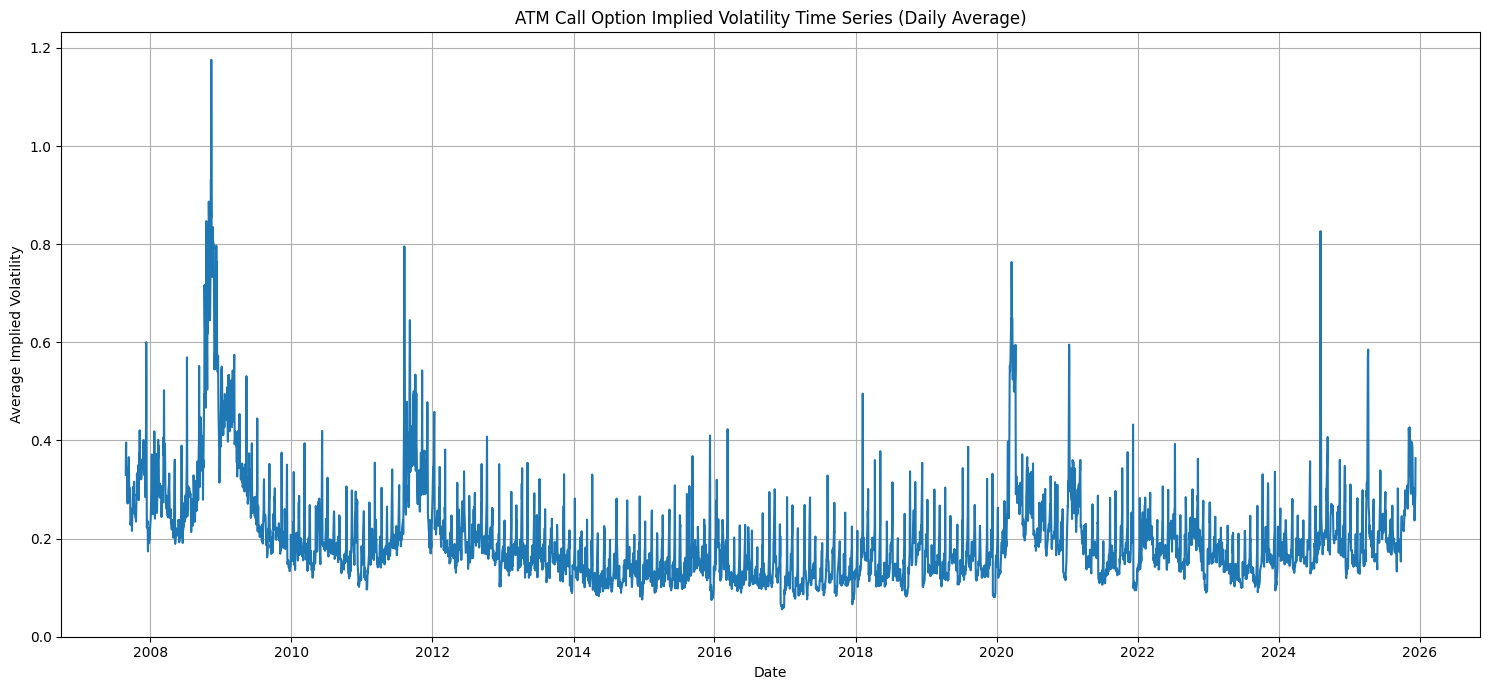

ATM 콜 옵션 내재변동성 시계열 그래프가 생성되었습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# '일자' 컬럼이 이미 datetime 형태로 변환되었다고 가정 (아니면 아래 주석 해제)
# df_calls['일자_datetime'] = pd.to_datetime(df_calls['일자'])

# ATM (At The Money) 옵션 필터링
# S (기초자산 가격)와 K (행사가격)의 비율이 특정 범위 안에 있는 옵션을 ATM으로 간주
# 예를 들어, K/S가 0.95 ~ 1.05 사이인 경우
# Implied_Volatility가 NaN이 아닌 값만 사용

# df_calls가 이미 존재한다고 가정하고, '일자'는 '일자_datetime'으로 가정
# 만약 '일자_datetime'이 없다면 '일자'를 사용하고, 필요시 pd.to_datetime으로 변환.
# 이전 코드에서 '일자_datetime' 컬럼이 추가되었으므로 이를 사용합니다.

df_calls_plot = df_calls.copy()
df_calls_plot['일자_datetime'] = pd.to_datetime(df_calls_plot['일자'], format='%Y/%m/%d (주간)')

atm_calls = df_calls_plot[
    (df_calls_plot['K'] / df_calls_plot['S'] >= 0.95) &
    (df_calls_plot['K'] / df_calls_plot['S'] <= 1.05) &
    (df_calls_plot['Implied_Volatility'].notna())
].copy()

print(f"필터링된 ATM 콜 옵션 데이터 수: {len(atm_calls)}")

if not atm_calls.empty:
    # 각 거래일의 평균 내재변동성 계산
    daily_iv = atm_calls.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()

    # 시계열 그래프 그리기
    plt.figure(figsize=(15, 7))
    sns.lineplot(x=daily_iv.index, y=daily_iv.values)
    plt.title('ATM Call Option Implied Volatility Time Series (Daily Average)')
    plt.xlabel('Date')
    plt.ylabel('Average Implied Volatility')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print("ATM 콜 옵션 내재변동성 시계열 그래프가 생성되었습니다.")
else:
    print("ATM 콜 옵션 데이터가 충분하지 않아 시계열 그래프를 생성할 수 없습니다.")

각 거래일의 ATM 근처 put 옵션에 대해 계산한 내재변동성 시계열

필터링된 ATM 풋 옵션 데이터 수: 46374


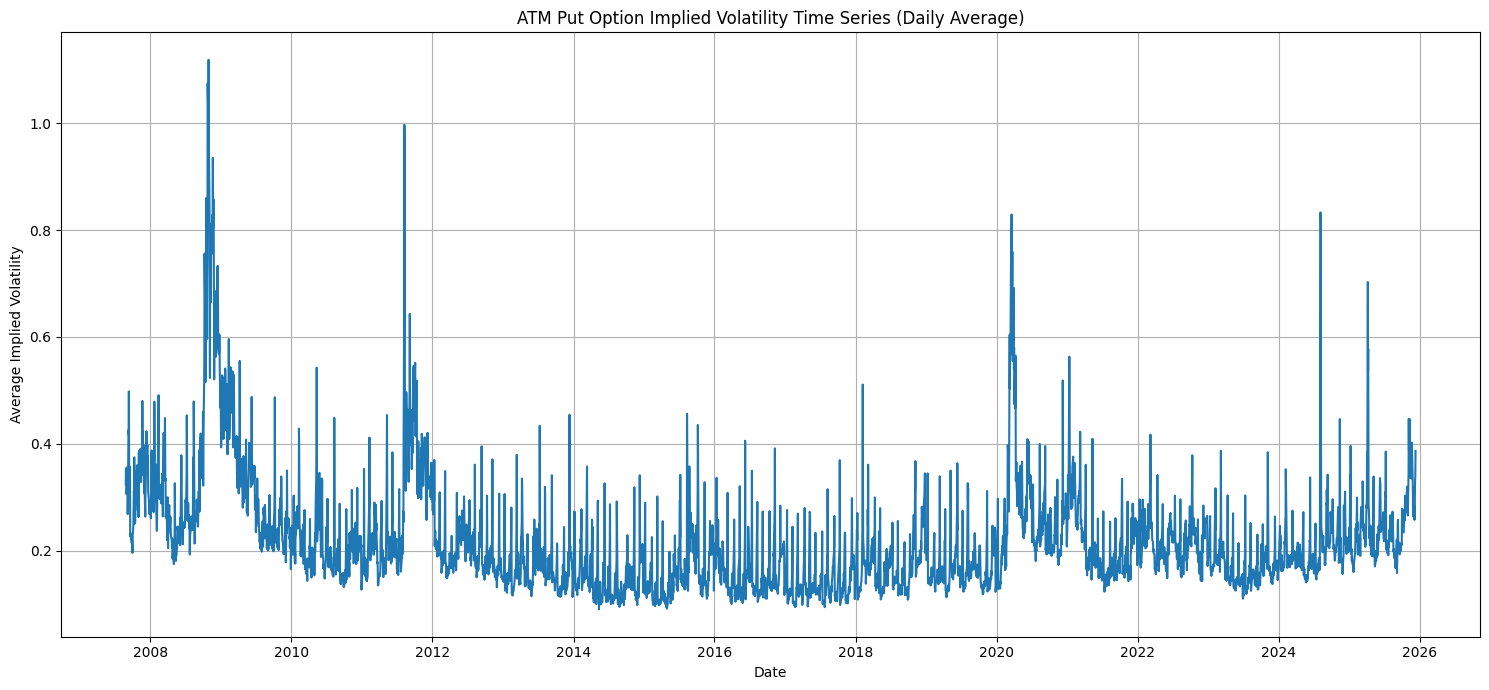

ATM 풋 옵션 내재변동성 시계열 그래프가 생성되었습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# df_puts는 이전 셀에서 df 변수로 할당되었으므로, df를 사용합니다.
df_puts_plot = df.copy()
df_puts_plot['일자_datetime'] = pd.to_datetime(df_puts_plot['일자'], format='%Y/%m/%d (주간)')

# ATM (At The Money) 옵션 필터링
# S (기초자산 가격)와 K (행사가격)의 비율이 특정 범위 안에 있는 옵션을 ATM으로 간주
# 예를 들어, K/S가 0.95 ~ 1.05 사이인 경우
# Implied_Volatility가 NaN이 아닌 값만 사용

atm_puts = df_puts_plot[
    (df_puts_plot['K'] / df_puts_plot['S'] >= 0.95) &
    (df_puts_plot['K'] / df_puts_plot['S'] <= 1.05) &
    (df_puts_plot['Implied_Volatility'].notna())
].copy()

print(f"필터링된 ATM 풋 옵션 데이터 수: {len(atm_puts)}")

if not atm_puts.empty:
    # 각 거래일의 평균 내재변동성 계산
    daily_iv_puts = atm_puts.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()

    # 시계열 그래프 그리기
    plt.figure(figsize=(15, 7))
    sns.lineplot(x=daily_iv_puts.index, y=daily_iv_puts.values)
    plt.title('ATM Put Option Implied Volatility Time Series (Daily Average)')
    plt.xlabel('Date')
    plt.ylabel('Average Implied Volatility')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print("ATM 풋 옵션 내재변동성 시계열 그래프가 생성되었습니다.")
else:
    print("ATM 풋 옵션 데이터가 충분하지 않아 시계열 그래프를 생성할 수 없습니다.")

K/St ≈ 0.9, 1.0, 1.1 인 call 옵션들의 내재변동성 시계열 비교

K/S Ratio 0.9 (Range: 0.875-0.925) 필터링된 콜 옵션 데이터 수: 6867
K/S Ratio 1.0 (Range: 0.975-1.025) 필터링된 콜 옵션 데이터 수: 24062
K/S Ratio 1.1 (Range: 1.075-1.125) 필터링된 콜 옵션 데이터 수: 18520


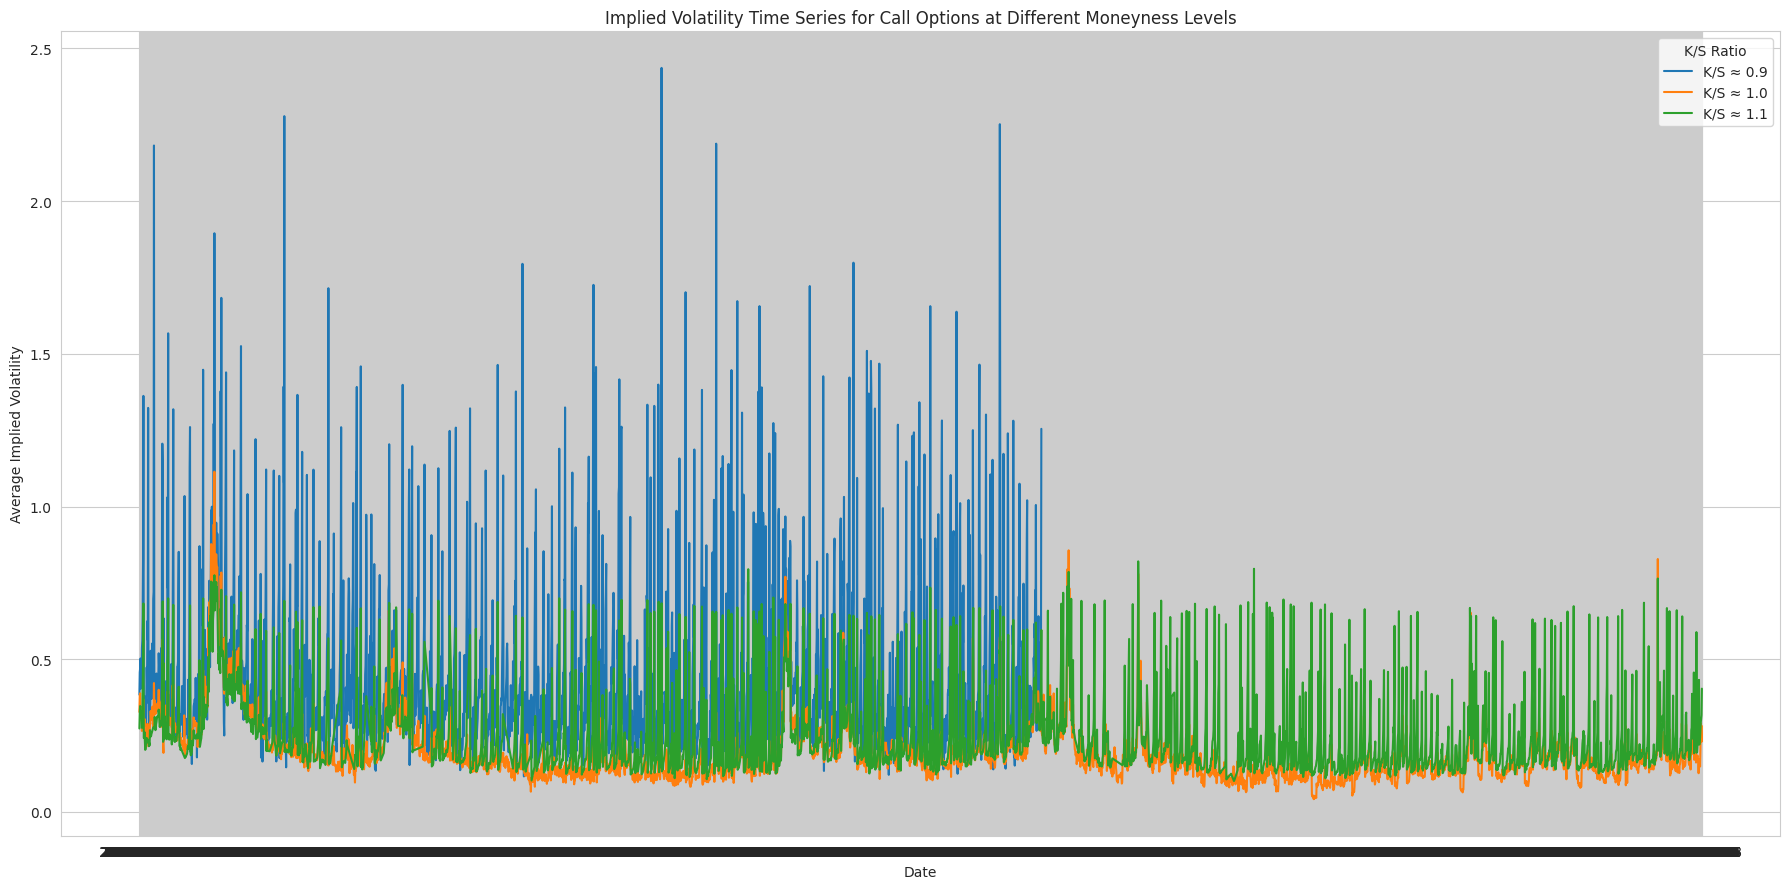

다양한 K/S 비율을 가진 콜 옵션의 내재변동성 시계열 비교 그래프가 생성되었습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# df_calls가 이미 준비되어 있고 '일자_datetime', 'S', 'K', 'Implied_Volatility' 컬럼을 포함한다고 가정합니다.

# K/S 비율을 계산합니다.
# 이미 df_calls_plot이 pd.to_datetime 처리되어 있으므로, 이를 사용합니다.
if '일자_datetime' not in df_calls.columns:
    df_calls_plot = df_calls.copy()
    df_calls_plot['일자_datetime'] = pd.to_datetime(df_calls_plot['일자'], format='%Y/%m/%d (주간)')
else:
    df_calls_plot = df_calls.copy()

df_calls_plot['K_S_Ratio'] = df_calls_plot['K'] / df_calls_plot['S']

moneyness_targets = [0.9, 1.0, 1.1] # 비교할 K/S 타겟 값
tolerance = 0.025 # K/S 비율의 허용 오차 (예: 0.9 -> 0.875 ~ 0.925)

plt.figure(figsize=(18, 9))
sns.set_style("whitegrid")

all_filtered_empty = True

for target_ratio in moneyness_targets:
    lower_bound = target_ratio - tolerance
    upper_bound = target_ratio + tolerance

    # 해당 K/S 비율 범위에 있고 내재변동성이 NaN이 아닌 콜 옵션 필터링
    filtered_calls = df_calls_plot[
        (df_calls_plot['K_S_Ratio'] >= lower_bound) &
        (df_calls_plot['K_S_Ratio'] <= upper_bound) &
        (df_calls_plot['Implied_Volatility'].notna())
    ].copy()

    print(f"K/S Ratio {target_ratio} (Range: {lower_bound:.3f}-{upper_bound:.3f}) 필터링된 콜 옵션 데이터 수: {len(filtered_calls)}")

    if not filtered_calls.empty:
        all_filtered_empty = False
        # 각 거래일의 평균 내재변동성 계산
        daily_iv_series = filtered_calls.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()

        # 시계열 그래프 그리기
        sns.lineplot(x=daily_iv_series.index, y=daily_iv_series.values, label=f'K/S ≈ {target_ratio:.1f}')
    else:
        print(f"경고: K/S Ratio {target_ratio}에 해당하는 데이터가 충분하지 않아 시계열 그래프를 그릴 수 없습니다.")

if not all_filtered_empty:
    plt.title('Implied Volatility Time Series for Call Options at Different Moneyness Levels')
    plt.xlabel('Date')
    plt.ylabel('Average Implied Volatility')
    plt.legend(title='K/S Ratio')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    print("다양한 K/S 비율을 가진 콜 옵션의 내재변동성 시계열 비교 그래프가 생성되었습니다.")
else:
    print("모든 K/S 비율에 대해 유효한 콜 옵션 데이터가 충분하지 않아 그래프를 생성할 수 없습니다.")

ATM straddle 가격과 ATM 내재변동성의 비교
Straddlet = CATM,t + PATM,t

'KOSPI200_final_liquid_filtered_with_TTM.csv' 파일을 성공적으로 로드하고 전처리했습니다.
병합된 ATM 스트래들 데이터 수: 43553
원본 데이터의 ATM 내재변동성(평균)을 병합했습니다.


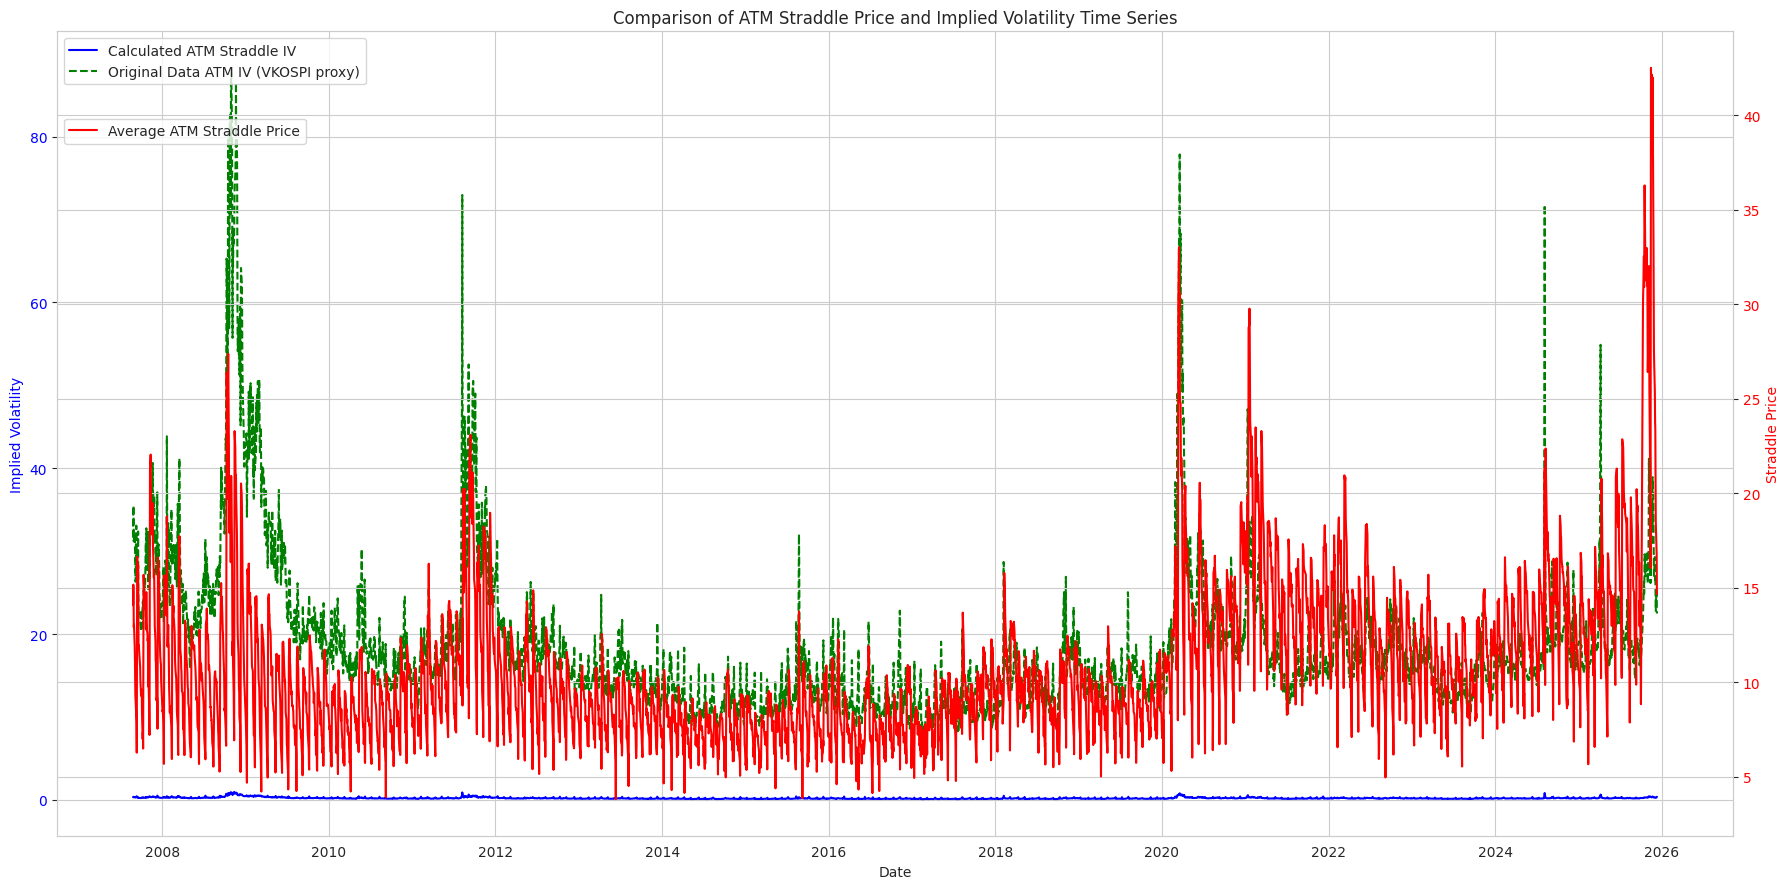

ATM 스트래들 가격 및 내재변동성 시계열 비교 그래프가 생성되었습니다.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 원본 데이터 로드 및 전처리 (내재변동성 비교를 위해)
file_path = 'KOSPI200_final_liquid_filtered_with_TTM.csv'
try:
    df_original_full = pd.read_csv(file_path)
    df_original_full['일자_datetime'] = pd.to_datetime(df_original_full['일자'], format='%Y/%m/%d (주간)')
    # S_t는 기초자산 가격 컬럼으로, 'S'로 통일하여 사용 (일관성을 위해)
    df_original_full['S'] = df_original_full['S_t']
    df_original_full['K_S_Ratio'] = df_original_full['K'] / df_original_full['S']
    print(f"'{file_path}' 파일을 성공적으로 로드하고 전처리했습니다.")
except FileNotFoundError:
    print(f"경고: '{file_path}' 파일을 찾을 수 없습니다. 원본 내재변동성 비교를 건너뜁니다.")
    df_original_full = pd.DataFrame()


# 2. ATM 콜 및 풋 옵션 데이터프레임 준비
# atm_calls와 atm_puts는 이미 이전 셀에서 생성되고 필터링된 상태라고 가정합니다.
# ATM 범위는 K/S ratio 0.95 ~ 1.05 입니다.

# 필요한 컬럼 선택 및 이름 변경
# 'r'과 'q' 컬럼을 추가합니다.
atm_calls_for_merge = atm_calls[['일자_datetime', 'S', 'K', 'r', 'q', 'TTM_years', 'C_mkt', 'Implied_Volatility']].rename(
    columns={'Implied_Volatility': 'IV_Call', 'C_mkt': 'Market_Call_Price'}
)
atm_puts_for_merge = atm_puts[['일자_datetime', 'S', 'K', 'r', 'q', 'TTM_years', 'P_mkt', 'Implied_Volatility']].rename(
    columns={'Implied_Volatility': 'IV_Put', 'P_mkt': 'Market_Put_Price'}
)

# 3. ATM 콜과 풋 옵션 병합하여 스트래들 구성
# 일자, 기초자산 가격, 행사가, 잔존만기가 동일한 콜/풋 옵션만을 병합
# 병합 키에 'r'과 'q'를 추가합니다.
merged_atm_straddles = pd.merge(atm_calls_for_merge, atm_puts_for_merge,
                                on=['일자_datetime', 'S', 'K', 'r', 'q', 'TTM_years'],
                                how='inner')

if merged_atm_straddles.empty:
    print("경고: 일치하는 ATM 콜/풋 옵션 쌍이 없어 스트래들 분석을 수행할 수 없습니다.")
else:
    print(f"병합된 ATM 스트래들 데이터 수: {len(merged_atm_straddles)}")

    # 4. 스트래들 가격 및 평균 내재변동성 계산
    merged_atm_straddles['Straddle_Price'] = merged_atm_straddles['Market_Call_Price'] + merged_atm_straddles['Market_Put_Price']
    merged_atm_straddles['Straddle_IV_Avg'] = (merged_atm_straddles['IV_Call'] + merged_atm_straddles['IV_Put']) / 2

    # 5. 각 거래일별 평균 스트래들 가격 및 내재변동성 집계
    daily_straddle_summary = merged_atm_straddles.groupby('일자_datetime').agg(
        Avg_Straddle_Price=('Straddle_Price', 'mean'),
        Avg_Calculated_Straddle_IV=('Straddle_IV_Avg', 'mean')
    ).sort_index()

    # 6. 원본 데이터의 ATM 내재변동성 (VKOSPI 등) 집계
    if not df_original_full.empty and '내재변동성' in df_original_full.columns:
        atm_original_iv_data = df_original_full[
            (df_original_full['K_S_Ratio'] >= 0.95) &
            (df_original_full['K_S_Ratio'] <= 1.05) &
            (df_original_full['내재변동성'].notna())
        ].copy()

        if not atm_original_iv_data.empty:
            daily_original_iv = atm_original_iv_data.groupby('일자_datetime')['내재변동성'].mean().sort_index()
            daily_straddle_summary = pd.merge(daily_straddle_summary, daily_original_iv.rename('Avg_Original_IV'),
                                              left_index=True, right_index=True, how='inner')
            print("원본 데이터의 ATM 내재변동성(평균)을 병합했습니다.")
        else:
            print("경고: 원본 데이터에서 ATM '내재변동성' 데이터를 찾을 수 없어 비교 분석에서 제외됩니다.")
    else:
        print("경고: 원본 데이터에 '내재변동성' 컬럼이 없거나, 데이터를 로드할 수 없어 비교 분석에서 제외됩니다.")

    # 7. 결과 시각화
    if not daily_straddle_summary.empty:
        plt.figure(figsize=(18, 9))
        sns.set_style("whitegrid")

        # Y축 1 (좌측): 내재변동성
        ax1 = sns.lineplot(data=daily_straddle_summary, x=daily_straddle_summary.index, y='Avg_Calculated_Straddle_IV', label='Calculated ATM Straddle IV', color='blue')
        if 'Avg_Original_IV' in daily_straddle_summary.columns:
            sns.lineplot(data=daily_straddle_summary, x=daily_straddle_summary.index, y='Avg_Original_IV', label='Original Data ATM IV (VKOSPI proxy)', color='green', linestyle='--')

        ax1.set_xlabel('Date')
        ax1.set_ylabel('Implied Volatility', color='blue')
        ax1.tick_params(axis='y', labelcolor='blue')
        ax1.legend(loc='upper left', bbox_to_anchor=(0.0, 1.0)) # 범례 위치 조정

        # Y축 2 (우측): 스트래들 가격
        ax2 = ax1.twinx()
        sns.lineplot(data=daily_straddle_summary, x=daily_straddle_summary.index, y='Avg_Straddle_Price', label='Average ATM Straddle Price', color='red', ax=ax2)
        ax2.set_ylabel('Straddle Price', color='red')
        ax2.tick_params(axis='y', labelcolor='red')
        ax2.legend(loc='upper left', bbox_to_anchor=(0.0, 0.9)) # 범례 위치 조정

        plt.title('Comparison of ATM Straddle Price and Implied Volatility Time Series')
        plt.grid(True)
        plt.tight_layout()
        plt.show()
        print("ATM 스트래들 가격 및 내재변동성 시계열 비교 그래프가 생성되었습니다.")
    else:
        print("그래프를 그릴 데이터가 충분하지 않습니다.")

**5. 기초통계량 산출**

$IV_{0.9,t}^{call}, IV_{1.0,t}^{call}, IV_{1.1,t}^{call}$

### 콜 옵션 내재변동성 (K/S ≈ 0.9, 1.0, 1.1) 기초 통계량 ###

K/S Ratio ≈ 0.9 (범위: 0.875-0.925) 내재변동성 통계량:


,Implied_Volatility
count,2478.000000
mean,0.444847
std,0.282060
min,0.114403
25%,0.268685
50%,0.355777
75%,0.513688
max,2.436272



K/S Ratio ≈ 1.0 (범위: 0.975-1.025) 내재변동성 통계량:


,Implied_Volatility
count,4292.000000
mean,0.193814
std,0.100537
min,0.041941
25%,0.133905
50%,0.169254
75%,0.218008
max,1.114102



K/S Ratio ≈ 1.1 (범위: 1.075-1.125) 내재변동성 통계량:


,Implied_Volatility
count,3844.000000
mean,0.249443
std,0.134120
min,0.101336
25%,0.162479
50%,0.201645
75%,0.270579
max,0.820546



### 콜 옵션 내재변동성 (K/S ≈ 0.9, 1.0, 1.1) 표본 분포 ###


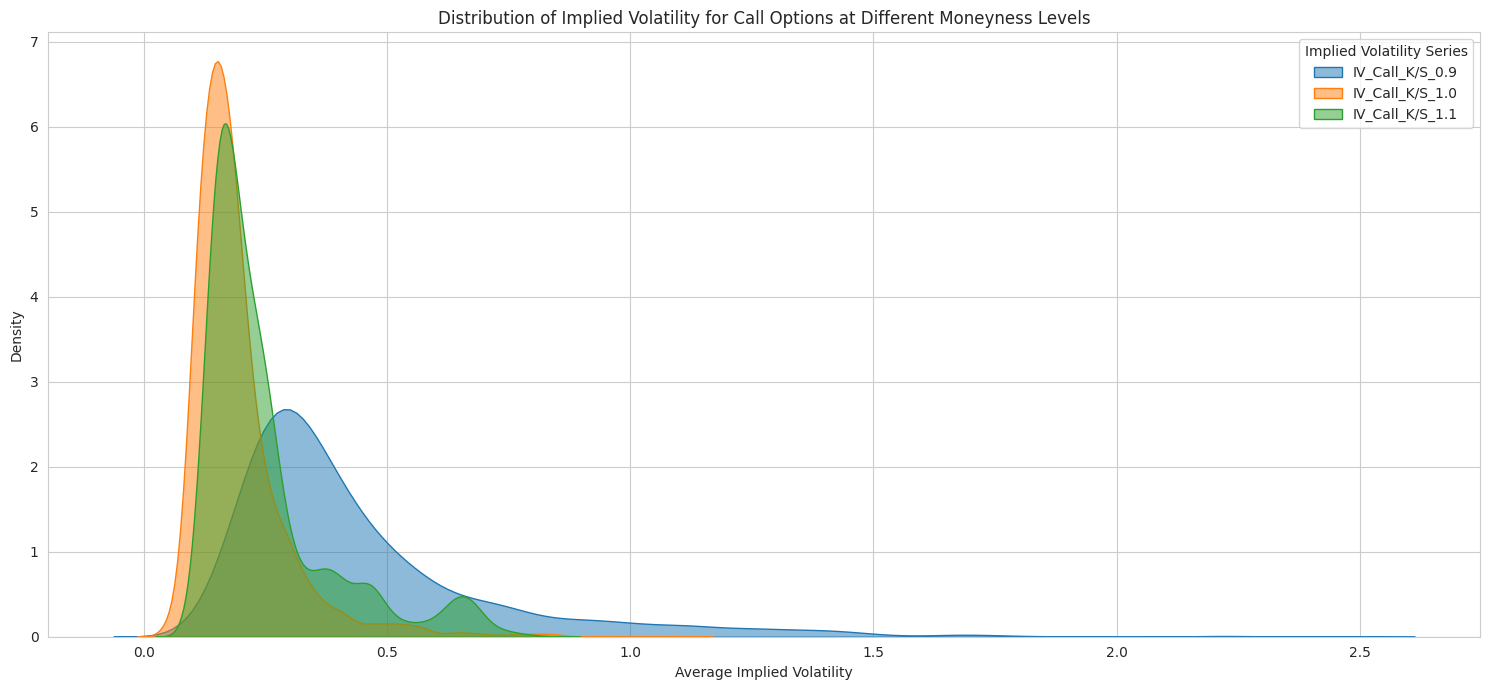

내재변동성 표본 분포 그래프가 생성되었습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# df_calls_plot은 이미 '일자_datetime', 'S', 'K', 'Implied_Volatility', 'K_S_Ratio' 컬럼을 포함한다고 가정합니다.
# 만약 df_calls_plot이 정의되지 않았다면 이전 셀의 코드를 재실행해야 합니다.
if 'df_calls_plot' not in locals():
    print("경고: 'df_calls_plot'이(가) 정의되지 않았습니다. 이전 셀을 실행하여 df_calls_plot을 먼저 생성해주세요.")
    # 최소한의 df_calls_plot 생성을 위한 코드 (실제 실행 시에는 주석 처리)
    # df_calls_plot = df_calls.copy()
    # df_calls_plot['일자_datetime'] = pd.to_datetime(df_calls_plot['일자'], format='%Y/%m/%d (주간)')
    # df_calls_plot['K_S_Ratio'] = df_calls_plot['K'] / df_calls_plot['S']

moneyness_targets = [0.9, 1.0, 1.1]
tolerance = 0.025 # K/S 비율의 허용 오차

iv_series_dict = {}

print("### 콜 옵션 내재변동성 (K/S ≈ 0.9, 1.0, 1.1) 기초 통계량 ###")

for target_ratio in moneyness_targets:
    lower_bound = target_ratio - tolerance
    upper_bound = target_ratio + tolerance

    filtered_calls = df_calls_plot[
        (df_calls_plot['K_S_Ratio'] >= lower_bound) &
        (df_calls_plot['K_S_Ratio'] <= upper_bound) &
        (df_calls_plot['Implied_Volatility'].notna())
    ].copy()

    if not filtered_calls.empty:
        daily_iv_series = filtered_calls.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()
        iv_series_dict[f'IV_Call_K/S_{target_ratio}'] = daily_iv_series

        print(f"\nK/S Ratio ≈ {target_ratio} (범위: {lower_bound:.3f}-{upper_bound:.3f}) 내재변동성 통계량:")
        display(daily_iv_series.describe())
    else:
        print(f"\n경고: K/S Ratio ≈ {target_ratio}에 해당하는 유효한 내재변동성 데이터가 충분하지 않습니다.")

# 2. 표본분포 그리기
print("\n### 콜 옵션 내재변동성 (K/S ≈ 0.9, 1.0, 1.1) 표본 분포 ###")

if iv_series_dict:
    plt.figure(figsize=(15, 7))
    sns.set_style("whitegrid")

    for label, series in iv_series_dict.items():
        if not series.empty:
            sns.kdeplot(series, label=label, fill=True, alpha=0.5)
        else:
            print(f"경고: {label}에 대한 데이터가 없어 분포 그래프를 그릴 수 없습니다.")

    plt.title('Distribution of Implied Volatility for Call Options at Different Moneyness Levels')
    plt.xlabel('Average Implied Volatility')
    plt.ylabel('Density')
    plt.legend(title='Implied Volatility Series')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    print("내재변동성 표본 분포 그래프가 생성되었습니다.")
else:
    print("분석할 내재변동성 데이터가 없어 분포 그래프를 생성할 수 없습니다.")

$IV_{0.9,t}^{put}, IV_{1.0,t}^{put}, IV_{1.1,t}^{put}$

### 풋 옵션 내재변동성 (K/S ≈ 0.9, 1.0, 1.1) 기초 통계량 ###

K/S Ratio ≈ 0.9 (범위: 0.875-0.925) 풋 옵션 내재변동성 통계량:


,Implied_Volatility
count,4151.000000
mean,0.325060
std,0.146813
min,0.148921
25%,0.227333
50%,0.275002
75%,0.368874
max,1.092942



K/S Ratio ≈ 1.0 (범위: 0.975-1.025) 풋 옵션 내재변동성 통계량:


,Implied_Volatility
count,4292.000000
mean,0.206430
std,0.104349
min,0.075943
25%,0.143128
50%,0.181378
75%,0.232723
max,1.063366



K/S Ratio ≈ 1.1 (범위: 1.075-1.125) 풋 옵션 내재변동성 통계량:


,Implied_Volatility
count,2541.000000
mean,0.399839
std,0.247739
min,0.108248
25%,0.248276
50%,0.323038
75%,0.450262
max,2.445092



### 풋 옵션 내재변동성 (K/S ≈ 0.9, 1.0, 1.1) 표본 분포 ###


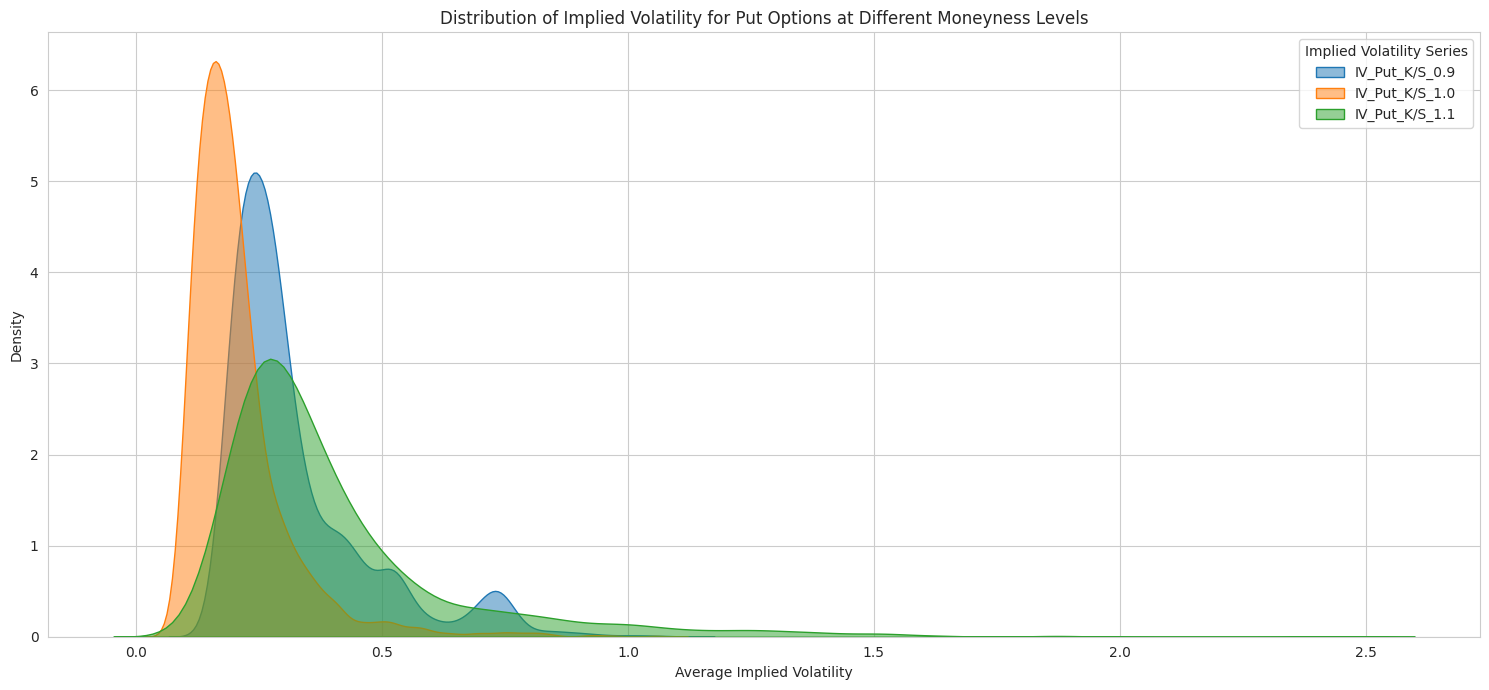

풋 옵션 내재변동성 표본 분포 그래프가 생성되었습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# df_puts_plot은 이미 '일자_datetime', 'S', 'K', 'Implied_Volatility', 'K_S_Ratio' 컬럼을 포함한다고 가정합니다.
# 만약 df_puts_plot이 정의되지 않았다면 이전 셀의 코드를 재실행해야 합니다.
if 'df_puts_plot' not in locals():
    print("경고: 'df_puts_plot'이(가) 정의되지 않았습니다. 이전 셀을 실행하여 df_puts_plot을 먼저 생성해주세요.")
    # 최소한의 df_puts_plot 생성을 위한 코드 (실제 실행 시에는 주석 처리)
    # df_puts_plot = df_puts.copy()
    # df_puts_plot['일자_datetime'] = pd.to_datetime(df_puts_plot['일자'], format='%Y/%m/%d (주간)')
    # df_puts_plot['K_S_Ratio'] = df_puts_plot['K'] / df_puts_plot['S']

moneyness_targets = [0.9, 1.0, 1.1]
tolerance = 0.025 # K/S 비율의 허용 오차

iv_series_dict_puts = {}

print("### 풋 옵션 내재변동성 (K/S ≈ 0.9, 1.0, 1.1) 기초 통계량 ###")

for target_ratio in moneyness_targets:
    lower_bound = target_ratio - tolerance
    upper_bound = target_ratio + tolerance

    filtered_puts = df_puts_plot[
        (df_puts_plot['K'] / df_puts_plot['S'] >= lower_bound) &
        (df_puts_plot['K'] / df_puts_plot['S'] <= upper_bound) &
        (df_puts_plot['Implied_Volatility'].notna())
    ].copy()

    # K_S_Ratio 컬럼이 없으면 생성
    if 'K_S_Ratio' not in filtered_puts.columns:
        filtered_puts['K_S_Ratio'] = filtered_puts['K'] / filtered_puts['S']

    if not filtered_puts.empty:
        daily_iv_series_puts = filtered_puts.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()
        iv_series_dict_puts[f'IV_Put_K/S_{target_ratio}'] = daily_iv_series_puts

        print(f"\nK/S Ratio ≈ {target_ratio} (범위: {lower_bound:.3f}-{upper_bound:.3f}) 풋 옵션 내재변동성 통계량:")
        display(daily_iv_series_puts.describe())
    else:
        print(f"\n경고: K/S Ratio ≈ {target_ratio}에 해당하는 유효한 풋 옵션 내재변동성 데이터가 충분하지 않습니다.")

# 2. 표본분포 그리기
print("\n### 풋 옵션 내재변동성 (K/S ≈ 0.9, 1.0, 1.1) 표본 분포 ###")

if iv_series_dict_puts:
    plt.figure(figsize=(15, 7))
    sns.set_style("whitegrid")

    for label, series in iv_series_dict_puts.items():
        if not series.empty:
            sns.kdeplot(series, label=label, fill=True, alpha=0.5)
        else:
            print(f"경고: {label}에 대한 데이터가 없어 분포 그래프를 그릴 수 없습니다.")

    plt.title('Distribution of Implied Volatility for Put Options at Different Moneyness Levels')
    plt.xlabel('Average Implied Volatility')
    plt.ylabel('Density')
    plt.legend(title='Implied Volatility Series')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    print("풋 옵션 내재변동성 표본 분포 그래프가 생성되었습니다.")
else:
    print("분석할 풋 옵션 내재변동성 데이터가 없어 분포 그래프를 생성할 수 없습니다.")

$IV_{ATM,t}^{call}$

### ATM 콜 옵션 내재변동성 기초 통계량 ###

ATM 콜 옵션 내재변동성 통계량:


,Implied_Volatility
count,4292.000000
mean,0.201030
std,0.102269
min,0.055899
25%,0.137415
50%,0.175046
75%,0.229411
max,1.175673



### ATM 콜 옵션 내재변동성 표본 분포 ###


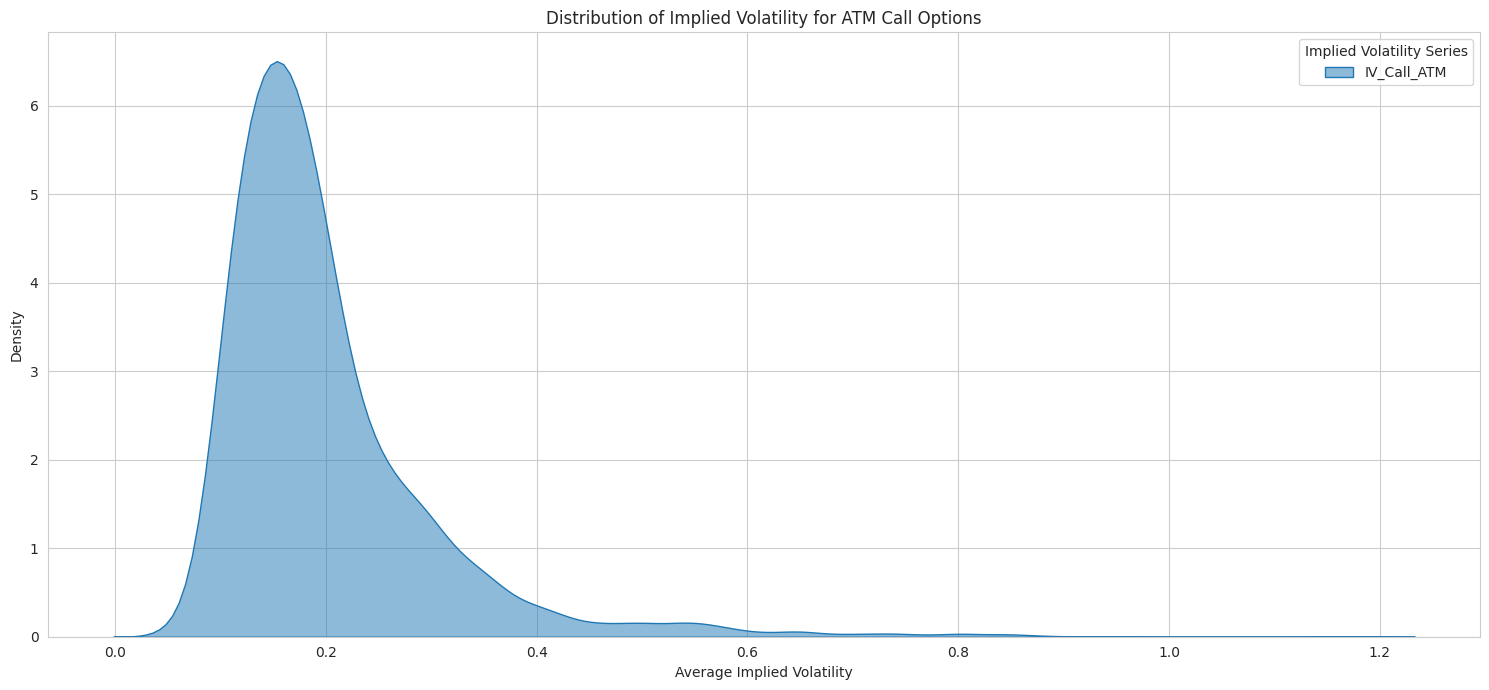

ATM 콜 옵션 내재변동성 표본 분포 그래프가 생성되었습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# daily_iv는 이전 셀에서 ATM 콜 옵션의 일별 평균 내재변동성 시계열로 생성되었습니다.
# atm_calls가 정의되어 있고 'Implied_Volatility' 컬럼을 포함한다고 가정합니다.
if 'daily_iv' not in locals() or daily_iv.empty:
    print("경고: 'daily_iv'가(이) 정의되지 않았거나 비어있습니다. 이전 셀을 실행하여 daily_iv를 먼저 생성해주세요.")
    # 예시 데이터프레임 생성 (실제 환경에서는 이전 셀에서 로드된 daily_iv 사용)
    # 이 예시 데이터는 실행되지 않고 경고만 출력됩니다.
    if 'atm_calls' in locals() and not atm_calls.empty:
        daily_iv = atm_calls.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()
    else:
        daily_iv = pd.Series([0.2, 0.22, 0.21, 0.23], index=pd.to_datetime(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04']))

iv_series_dict_atm_calls = {}

print("### ATM 콜 옵션 내재변동성 기초 통계량 ###")

iv_series_dict_atm_calls['IV_Call_ATM'] = daily_iv

if not daily_iv.empty:
    print(f"\nATM 콜 옵션 내재변동성 통계량:")
    display(daily_iv.describe())
else:
    print(f"\n경고: ATM 콜 옵션에 해당하는 유효한 내재변동성 데이터가 충분하지 않습니다.")

# 2. 표본분포 그리기
print("\n### ATM 콜 옵션 내재변동성 표본 분포 ###")

if iv_series_dict_atm_calls:
    plt.figure(figsize=(15, 7))
    sns.set_style("whitegrid")

    for label, series in iv_series_dict_atm_calls.items():
        if not series.empty:
            sns.kdeplot(series, label=label, fill=True, alpha=0.5)
        else:
            print(f"경고: {label}에 대한 데이터가 없어 분포 그래프를 그릴 수 없습니다.")

    plt.title(f'Distribution of Implied Volatility for ATM Call Options')
    plt.xlabel('Average Implied Volatility')
    plt.ylabel('Density')
    plt.legend(title='Implied Volatility Series')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    print("ATM 콜 옵션 내재변동성 표본 분포 그래프가 생성되었습니다.")
else:
    print("분석할 ATM 콜 옵션 내재변동성 데이터가 없어 분포 그래프를 생성할 수 없습니다.")

$IV_{ATM,t}^{put}$

### ATM 풋 옵션 내재변동성 기초 통계량 ###

ATM 풋 옵션 내재변동성 통계량:


,Implied_Volatility
count,4292.000000
mean,0.217849
std,0.105982
min,0.091009
25%,0.151951
50%,0.191984
75%,0.247721
max,1.118205



### ATM 풋 옵션 내재변동성 표본 분포 ###


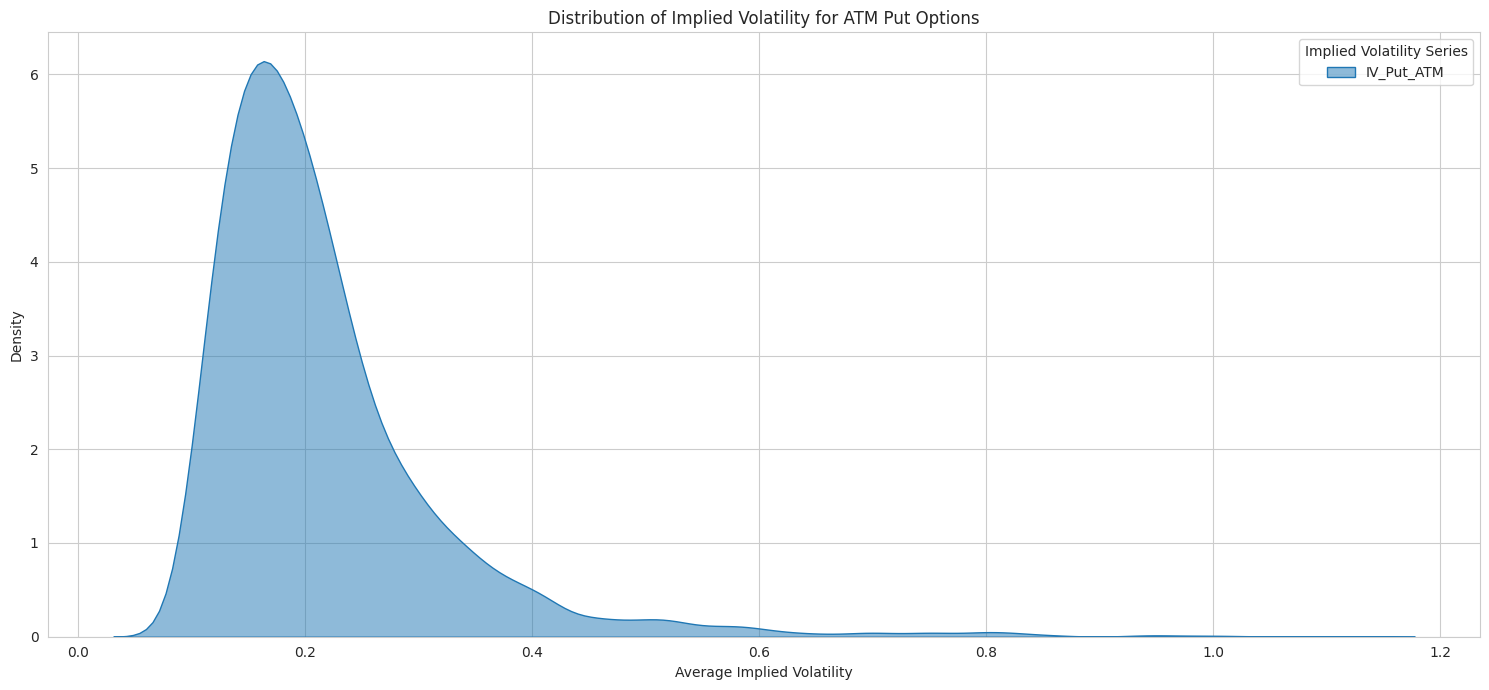

ATM 풋 옵션 내재변동성 표본 분포 그래프가 생성되었습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# daily_iv_series_atm_puts는 이전 셀에서 ATM 풋 옵션의 일별 평균 내재변동성 시계열로 생성되었습니다.
# atm_puts가 정의되어 있고 'Implied_Volatility' 컬럼을 포함한다고 가정합니다.
if 'daily_iv_series_atm_puts' not in locals() or daily_iv_series_atm_puts.empty:
    print("경고: 'daily_iv_series_atm_puts'이(가) 정의되지 않았거나 비어있습니다. 이전 셀을 실행하여 daily_iv_series_atm_puts를 먼저 생성해주세요.")
    # 예시 데이터프레임 생성 (실제 환경에서는 이전 셀에서 로드된 daily_iv_series_atm_puts 사용)
    # 이 예시 데이터는 실행되지 않고 경고만 출력됩니다.
    if 'atm_puts' in locals() and not atm_puts.empty:
        daily_iv_series_atm_puts = atm_puts.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()
    else:
        daily_iv_series_atm_puts = pd.Series([0.2, 0.22, 0.21, 0.23], index=pd.to_datetime(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04']))

iv_series_dict_atm_puts = {}

print("### ATM 풋 옵션 내재변동성 기초 통계량 ###")

iv_series_dict_atm_puts['IV_Put_ATM'] = daily_iv_series_atm_puts

if not daily_iv_series_atm_puts.empty:
    print(f"\nATM 풋 옵션 내재변동성 통계량:")
    display(daily_iv_series_atm_puts.describe())
else:
    print(f"\n경고: ATM 풋 옵션에 해당하는 유효한 내재변동성 데이터가 충분하지 않습니다.")

# 2. 표본분포 그리기
print("\n### ATM 풋 옵션 내재변동성 표본 분포 ###")

if iv_series_dict_atm_puts:
    plt.figure(figsize=(15, 7))
    sns.set_style("whitegrid")

    for label, series in iv_series_dict_atm_puts.items():
        if not series.empty:
            sns.kdeplot(series, label=label, fill=True, alpha=0.5)
        else:
            print(f"경고: {label}에 대한 데이터가 없어 분포 그래프를 그릴 수 없습니다.")

    plt.title(f'Distribution of Implied Volatility for ATM Put Options')
    plt.xlabel('Average Implied Volatility')
    plt.ylabel('Density')
    plt.legend(title='Implied Volatility Series')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    print("ATM 풋 옵션 내재변동성 표본 분포 그래프가 생성되었습니다.")
else:
    print("분석할 ATM 풋 옵션 내재변동성 데이터가 없어 분포 그래프를 생성할 수 없습니다.")

$Straddle_{t}$

### ATM 스트래들 가격 기초 통계량 ###

ATM 스트래들 가격 통계량:


,Avg_Straddle_Price
count,4292.000000
mean,10.653186
std,4.065692
min,3.815000
25%,7.946562
50%,9.775265
75%,12.347548
max,42.505263



### ATM 스트래들 가격 표본 분포 ###


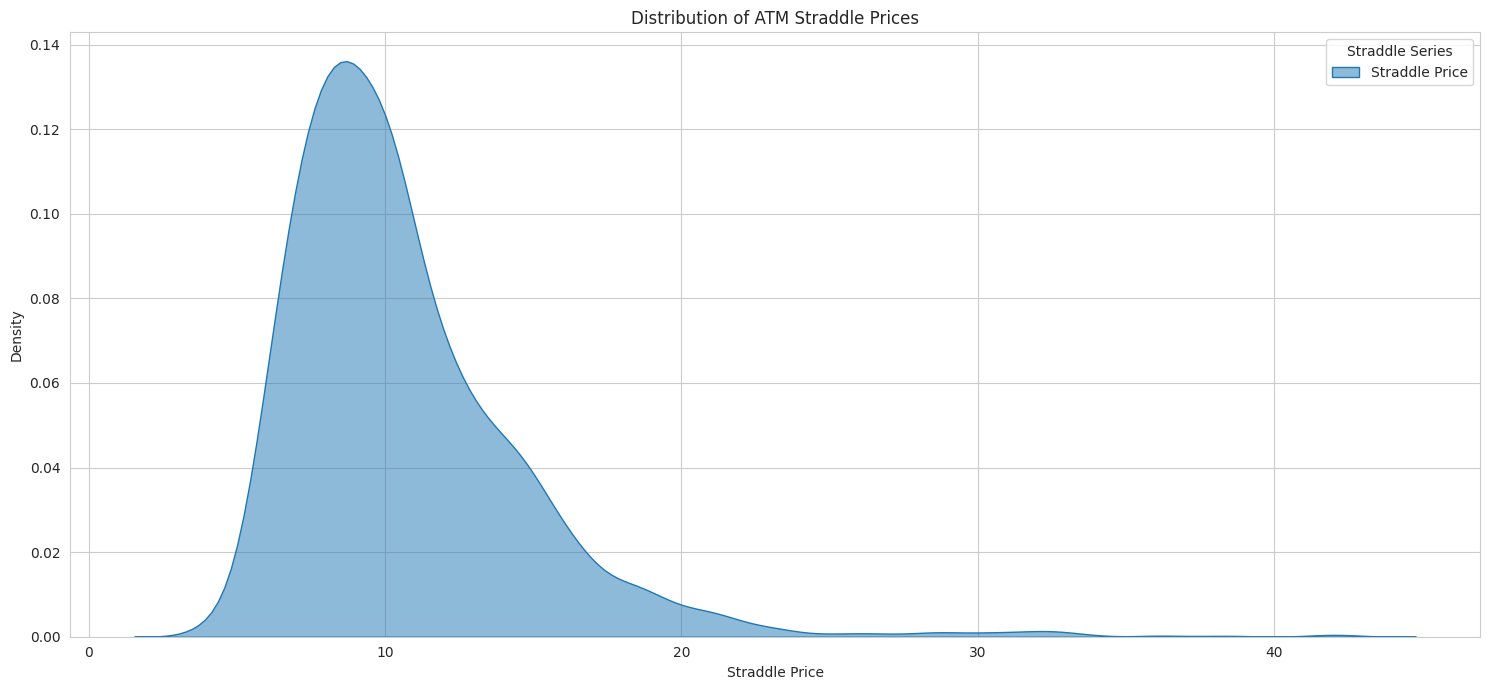

ATM 스트래들 가격 표본 분포 그래프가 생성되었습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# daily_straddle_summary는 이전 셀에서 생성되었으며 'Avg_Straddle_Price' 컬럼을 포함합니다.
if 'daily_straddle_summary' not in locals() or daily_straddle_summary.empty:
    print("경고: 'daily_straddle_summary'이(가) 정의되지 않았거나 비어있습니다. 이전 셀을 실행하여 daily_straddle_summary를 먼저 생성해주세요.")
    # 예시 데이터 생성 (실제 환경에서는 이전 셀에서 로드된 daily_straddle_summary 사용)
    daily_straddle_summary = pd.DataFrame({
        'Avg_Straddle_Price': [10.5, 11.2, 10.8, 11.5, 12.0],
        'Avg_Calculated_Straddle_IV': [0.2, 0.22, 0.21, 0.23, 0.24],
        'Avg_Original_IV': [0.21, 0.23, 0.22, 0.24, 0.25]
    }, index=pd.to_datetime(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04', '2023-01-05']))

straddle_price_series = daily_straddle_summary['Avg_Straddle_Price']

print("### ATM 스트래들 가격 기초 통계량 ###")

if not straddle_price_series.empty:
    print("\nATM 스트래들 가격 통계량:")
    display(straddle_price_series.describe())
else:
    print("\n경고: ATM 스트래들 가격 데이터가 충분하지 않습니다.")

# 2. 표본분포 그리기
print("\n### ATM 스트래들 가격 표본 분포 ###")

if not straddle_price_series.empty:
    plt.figure(figsize=(15, 7))
    sns.set_style("whitegrid")

    sns.kdeplot(straddle_price_series, label='Straddle Price', fill=True, alpha=0.5)

    plt.title('Distribution of ATM Straddle Prices')
    plt.xlabel('Straddle Price')
    plt.ylabel('Density')
    plt.legend(title='Straddle Series')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    print("ATM 스트래들 가격 표본 분포 그래프가 생성되었습니다.")
else:
    print("분석할 ATM 스트래들 가격 데이터가 없어 분포 그래프를 생성할 수 없습니다.")

**6. 추가 분석**

내재변동성으로부터 volatility skew를 계산/ 시계열로 구성


### Volatility Skew (K/S=0.9 - K/S=1.0) 시계열 통계량 ###


,Volatility_Skew
count,4151.000000
mean,0.120799
std,0.100863
min,-0.045027
25%,0.063994
50%,0.089567
75%,0.131999
max,0.596487


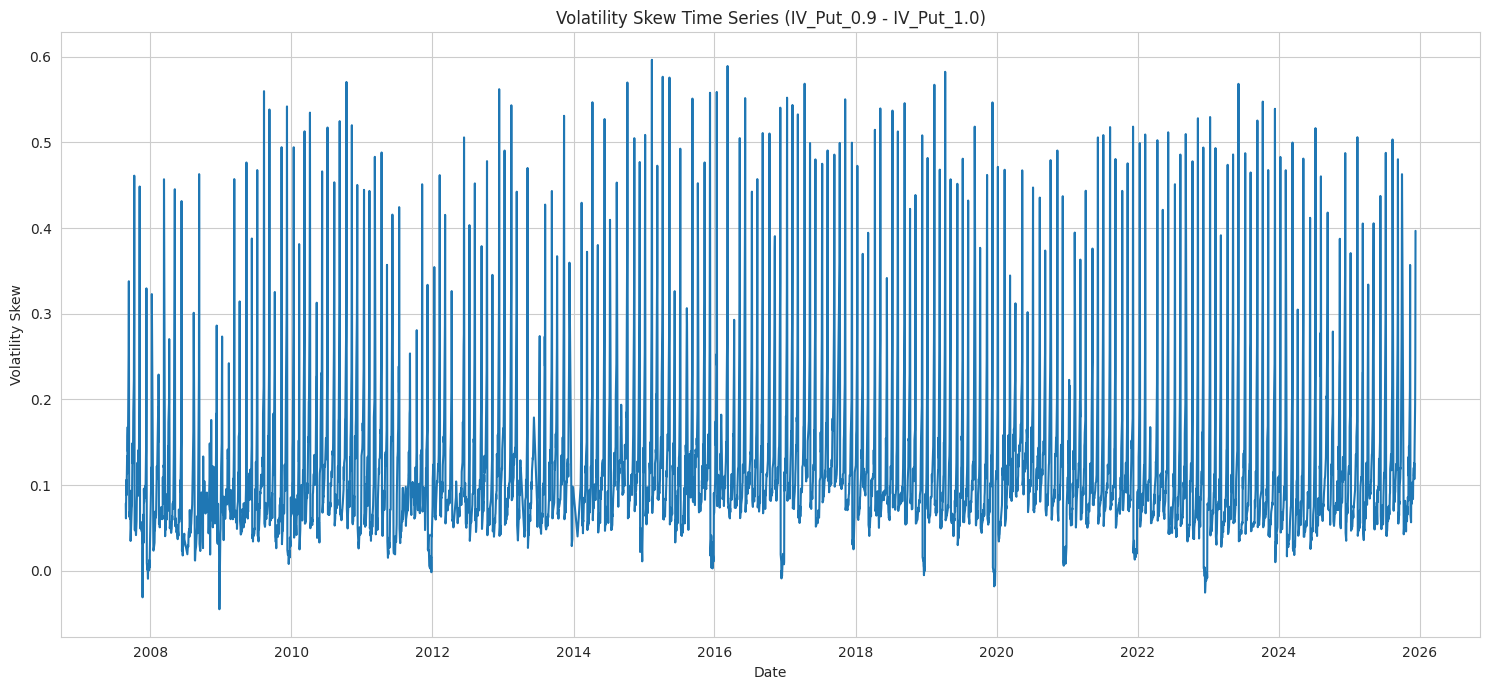

Volatility Skew 시계열 그래프가 생성되었습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 이전 셀에서 생성된 iv_series_dict_puts를 사용합니다.
# 이 딕셔너리에는 K/S 비율별 풋 옵션의 일별 평균 내재변동성 시계열이 포함되어 있습니다.
if 'iv_series_dict_puts' not in locals() or not iv_series_dict_puts:
    print("경고: 'iv_series_dict_puts'이(가) 정의되지 않았거나 비어있습니다. 이전 셀을 실행하여 해당 변수를 생성해주세요.")
else:
    # 필요한 내재변동성 시계열 추출
    iv_put_0_9 = iv_series_dict_puts.get('IV_Put_K/S_0.9')
    iv_put_1_0 = iv_series_dict_puts.get('IV_Put_K/S_1.0')

    if iv_put_0_9 is None or iv_put_1_0 is None:
        print("경고: Volatility Skew 계산에 필요한 'IV_Put_K/S_0.9' 또는 'IV_Put_K/S_1.0' 데이터가 없습니다.")
    else:
        # 두 시계열의 인덱스를 정렬하여 빼기 연산을 수행합니다.
        # 양쪽 모두 존재하는 날짜에 대해서만 계산하기 위해 outer join 후 dropna를 사용합니다.
        combined_iv = pd.concat([iv_put_0_9.rename('IV_Put_0.9'), iv_put_1_0.rename('IV_Put_1.0')], axis=1)
        combined_iv.dropna(inplace=True)

        if not combined_iv.empty:
            # Volatility Skew 계산: Skew_t = IV_put(0.9,t) - IV_put(1.0,t)
            combined_iv['Volatility_Skew'] = combined_iv['IV_Put_0.9'] - combined_iv['IV_Put_1.0']

            print("\n### Volatility Skew (K/S=0.9 - K/S=1.0) 시계열 통계량 ###")
            display(combined_iv['Volatility_Skew'].describe())

            # Volatility Skew 시계열 그래프 그리기
            plt.figure(figsize=(15, 7))
            sns.set_style("whitegrid")
            sns.lineplot(x=combined_iv.index, y=combined_iv['Volatility_Skew'])
            plt.title('Volatility Skew Time Series (IV_Put_0.9 - IV_Put_1.0)')
            plt.xlabel('Date')
            plt.ylabel('Volatility Skew')
            plt.grid(True)
            plt.tight_layout()
            plt.show()
            print("Volatility Skew 시계열 그래프가 생성되었습니다.")
        else:
            print("경고: Volatility Skew를 계산하기 위한 충분한 데이터가 없습니다. (K/S=0.9 및 K/S=1.0 풋옵션 내재변동성 매칭 실패)")

동일한 옵션에 대해 call 기반 IV와 put 기반 IV를 비교하고, put-call parity 관점에서
해석

### 콜/풋 IV 비교 및 풋-콜 패리티 분석 ###

### Call IV - Put IV 및 Put-Call Parity Deviation 시계열 통계량 ###

Average Implied Volatility (Call - Put) Statistics:


,Avg_IV_Call_Minus_Put
count,4292.000000
mean,-0.015430
std,0.057010
min,-0.456372
25%,-0.037582
50%,-0.010885
75%,0.011175
max,0.419391



Put-Call Parity Deviation Statistics:


,Avg_PCP_Deviation
count,4292.000000
mean,-0.305241
std,0.855871
min,-6.566067
25%,-0.548914
50%,-0.144274
75%,0.146670
max,1.836279


/tmp/ipykernel_1558/3243896345.py:64: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1558/3243896345.py:64: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


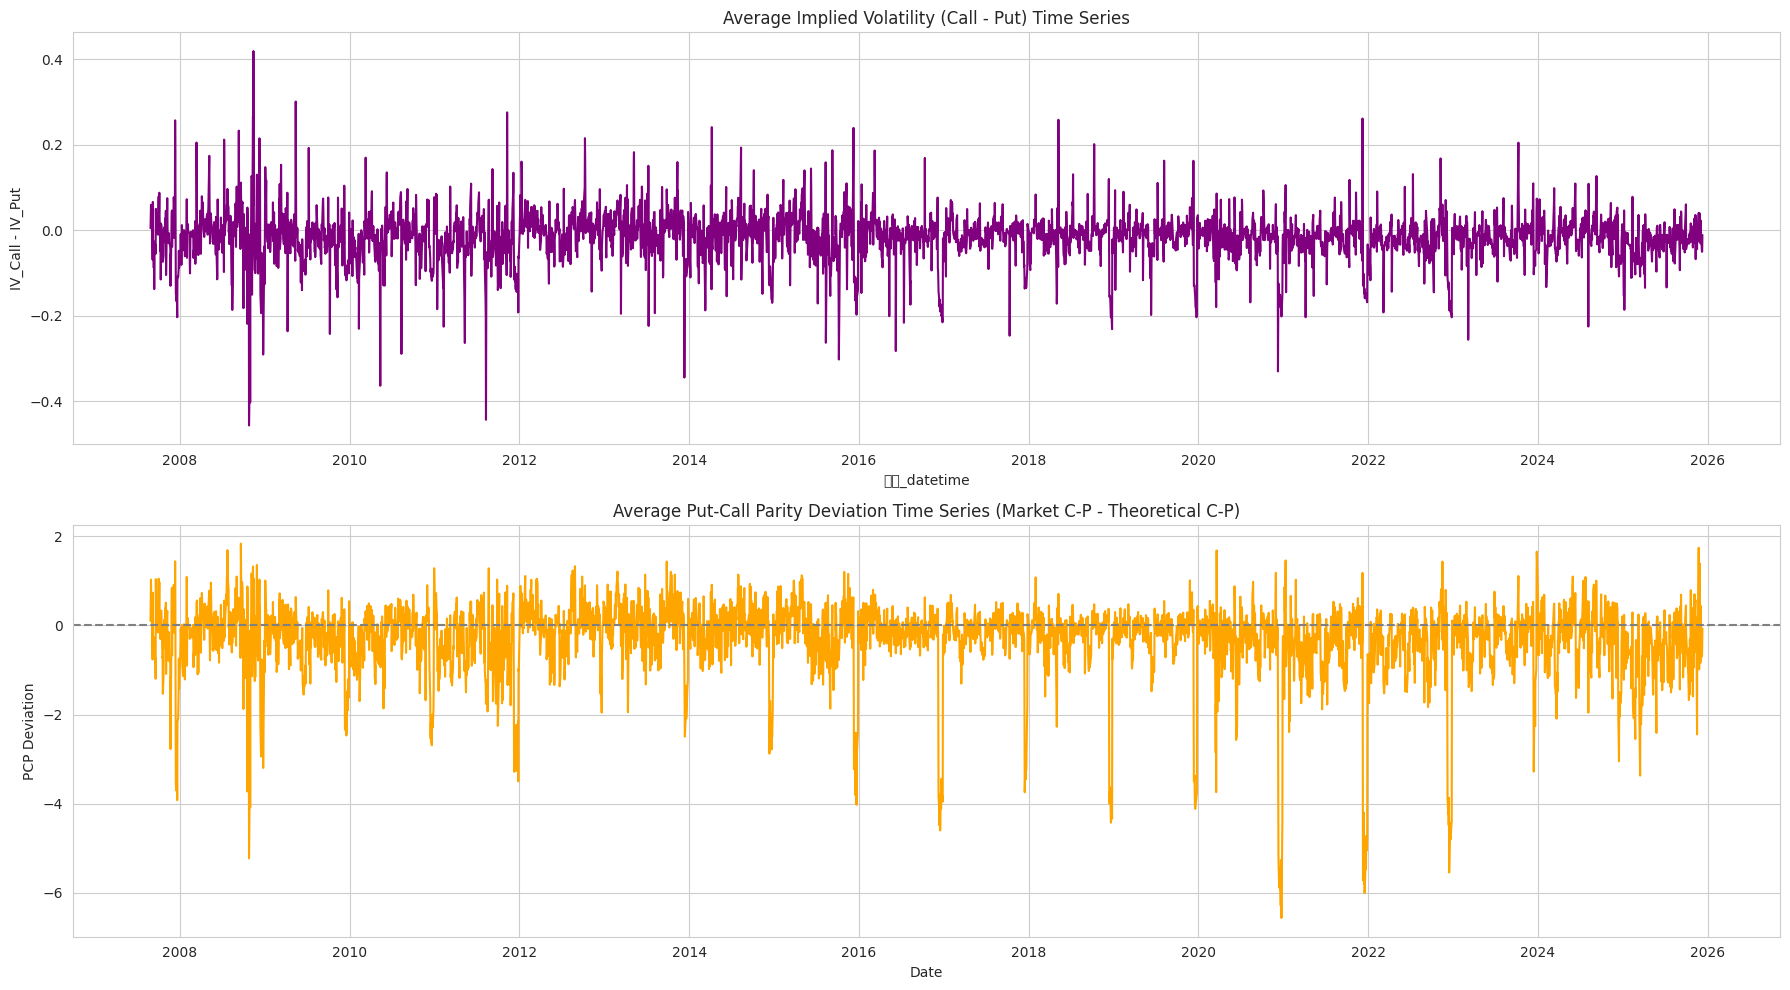


콜 IV와 풋 IV의 차이 및 풋-콜 패리티 불일치 시계열 그래프가 생성되었습니다.

### 풋-콜 패리티 해석 ###
콜 IV와 풋 IV의 차이는 시장이 동일한 옵션에 대해 콜과 풋을 다르게 평가하는 정도를 나타냅니다.
풋-콜 패리티 불일치(PCP_Deviation)는 시장 가격(C-P)이 이론적인 패리티 관계(S*exp(-qT) - K*exp(-rT))에서 얼마나 벗어나는지를 보여줍니다.
이론적으로는 PCP_Deviation이 0에 가까워야 차익거래 기회가 없음을 의미합니다. 양수 또는 음수로 크게 벗어나는 경우 차익거래 기회 또는 시장의 비효율성을 시사할 수 있습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 이전 단계에서 생성된 `merged_atm_straddles` DataFrame을 사용합니다.
# 이 DataFrame은 동일한 날짜, 기초자산, 행사가, 잔존만기를 가진 콜/풋 옵션 쌍을 포함합니다.
if 'merged_atm_straddles' not in locals() or merged_atm_straddles.empty:
    print("경고: 'merged_atm_straddles'이(가) 정의되지 않았거나 비어있습니다. 이전 셀들을 실행하여 해당 변수를 생성해주세요.")
else:
    print("### 콜/풋 IV 비교 및 풋-콜 패리티 분석 ###")

    df_parity_analysis = merged_atm_straddles.copy()

    # 1. Call IV와 Put IV의 차이 계산
    df_parity_analysis['IV_Call_Minus_Put'] = df_parity_analysis['IV_Call'] - df_parity_analysis['IV_Put']

    # 2. 풋-콜 패리티(Put-Call Parity) 좌변 (C - P) 계산
    df_parity_analysis['Market_CP_Diff'] = df_parity_analysis['Market_Call_Price'] - df_parity_analysis['Market_Put_Price']

    # 3. 풋-콜 패리티 우변 (S * exp(-qT) - K * exp(-rT)) 계산
    # r, q, T 컬럼이 df_parity_analysis에 존재한다고 가정합니다.
    # np.exp(-q * T) 대신 (1-q*T)를 사용하거나, q가 0일 경우 exp(-0*T) = 1 이므로 S_t로 간주될 수 있습니다.
    # 현재 q가 0.0으로 가정되어 있으므로, S * np.exp(-q*T)는 S로 단순화될 수 있으나, 정확한 모델을 위해 exp 함수를 사용합니다.
    df_parity_analysis['Theoretical_CP_Diff'] = \
        df_parity_analysis['S'] * np.exp(-df_parity_analysis['q'] * df_parity_analysis['TTM_years']) - \
        df_parity_analysis['K'] * np.exp(-df_parity_analysis['r'] * df_parity_analysis['TTM_years'])

    # 4. 풋-콜 패리티 불일치 (Deviation from PCP) 계산
    df_parity_analysis['PCP_Deviation'] = df_parity_analysis['Market_CP_Diff'] - df_parity_analysis['Theoretical_CP_Diff']

    # 일별 평균 집계
    daily_parity_summary = df_parity_analysis.groupby('일자_datetime').agg(
        Avg_IV_Call_Minus_Put=('IV_Call_Minus_Put', 'mean'),
        Avg_PCP_Deviation=('PCP_Deviation', 'mean')
    ).sort_index()

    print("\n### Call IV - Put IV 및 Put-Call Parity Deviation 시계열 통계량 ###")
    print("\nAverage Implied Volatility (Call - Put) Statistics:")
    display(daily_parity_summary['Avg_IV_Call_Minus_Put'].describe())
    print("\nPut-Call Parity Deviation Statistics:")
    display(daily_parity_summary['Avg_PCP_Deviation'].describe())

    # 5. 시계열 그래프 그리기
    plt.figure(figsize=(18, 10))
    sns.set_style("whitegrid")

    # Subplot 1: Call IV - Put IV
    plt.subplot(2, 1, 1)
    sns.lineplot(x=daily_parity_summary.index, y=daily_parity_summary['Avg_IV_Call_Minus_Put'], color='purple')
    plt.title('Average Implied Volatility (Call - Put) Time Series')
    plt.ylabel('IV_Call - IV_Put')
    plt.grid(True)

    # Subplot 2: Put-Call Parity Deviation
    plt.subplot(2, 1, 2)
    sns.lineplot(x=daily_parity_summary.index, y=daily_parity_summary['Avg_PCP_Deviation'], color='orange')
    plt.title('Average Put-Call Parity Deviation Time Series (Market C-P - Theoretical C-P)')
    plt.xlabel('Date')
    plt.ylabel('PCP Deviation')
    plt.grid(True)
    plt.axhline(0, color='gray', linestyle='--') # 0 라인 추가

    plt.tight_layout()
    plt.show()

    print("\n콜 IV와 풋 IV의 차이 및 풋-콜 패리티 불일치 시계열 그래프가 생성되었습니다.")
    print("\n### 풋-콜 패리티 해석 ###")
    print("콜 IV와 풋 IV의 차이는 시장이 동일한 옵션에 대해 콜과 풋을 다르게 평가하는 정도를 나타냅니다.")
    print("풋-콜 패리티 불일치(PCP_Deviation)는 시장 가격(C-P)이 이론적인 패리티 관계(S*exp(-qT) - K*exp(-rT))에서 얼마나 벗어나는지를 보여줍니다.")
    print("이론적으로는 PCP_Deviation이 0에 가까워야 차익거래 기회가 없음을 의미합니다. 양수 또는 음수로 크게 벗어나는 경우 차익거래 기회 또는 시장의 비효율성을 시사할 수 있습니다.")

만기 직전 구간을 포함한 경우와 제외한 경우의 내재변동성 결과를 비교

### 잔존만기 30일 (0.082년) 기준으로 내재변동성 비교 ###

--- 콜 옵션 내재변동성 분석 ---
만기 직전 콜 옵션 데이터 수 (30일 이하): 110065개
만기 장기 콜 옵션 데이터 수 (30일 초과): 4335개


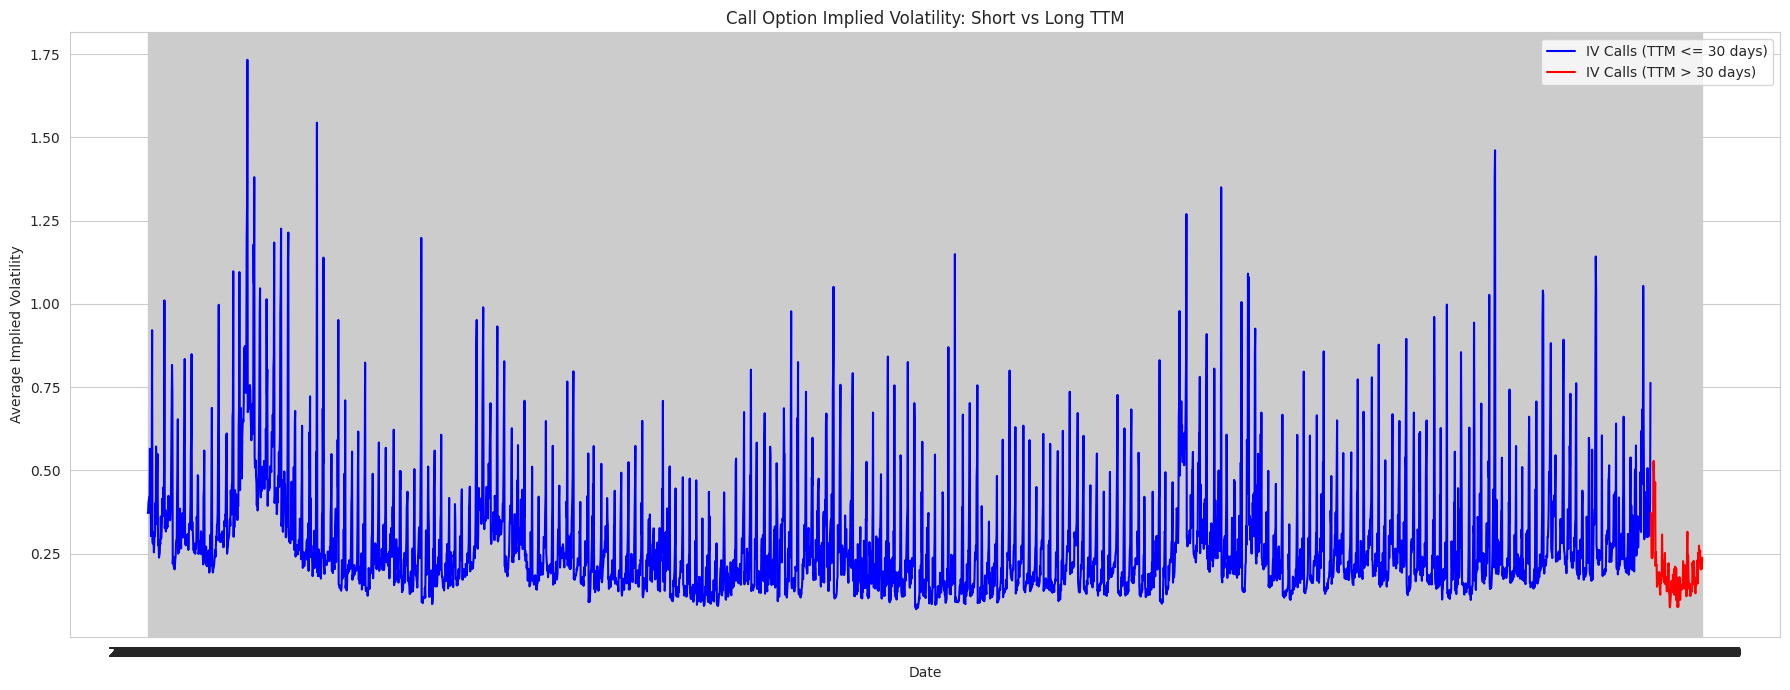

콜 옵션 만기 직전/장기 내재변동성 비교 그래프가 생성되었습니다.

--- 풋 옵션 내재변동성 분석 ---
만기 직전 풋 옵션 데이터 수 (30일 이하): 143302개
만기 장기 풋 옵션 데이터 수 (30일 초과): 5545개


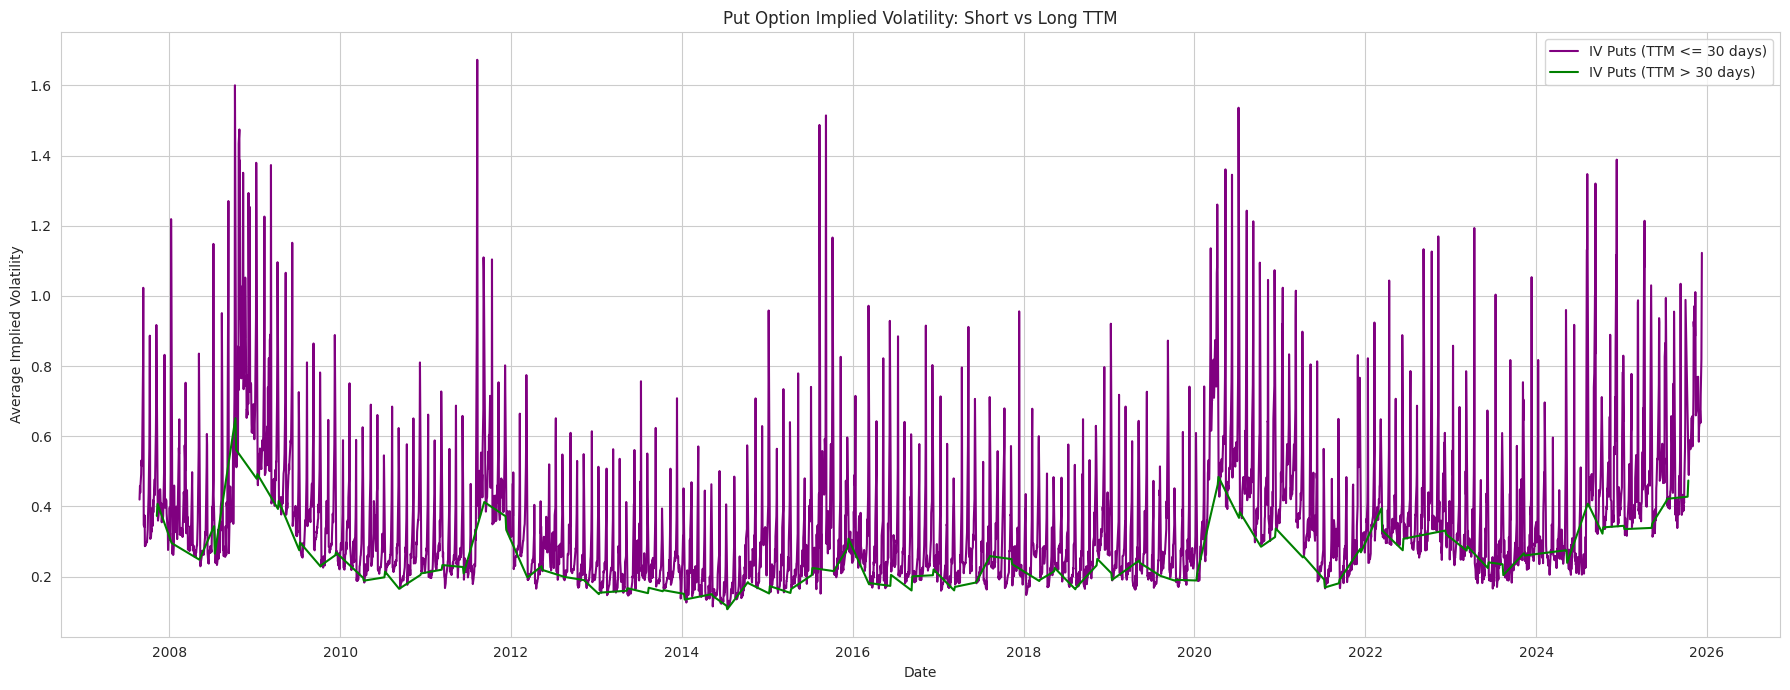

풋 옵션 만기 직전/장기 내재변동성 비교 그래프가 생성되었습니다.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# TTM_years (잔존만기) 기준 설정 (예: 30일 = 30/365.25년)
TTM_THRESHOLD_DAYS = 30
TTM_THRESHOLD_YEARS = TTM_THRESHOLD_DAYS / 365.25

print(f"### 잔존만기 {TTM_THRESHOLD_DAYS}일 ({TTM_THRESHOLD_YEARS:.3f}년) 기준으로 내재변동성 비교 ###")

# --- 콜 옵션 분석 ---
print("\n--- 콜 옵션 내재변동성 분석 ---")

# df_calls_plot이 이전 셀에서 정의되었는지 확인합니다.
if 'df_calls_plot' not in locals() or df_calls_plot.empty:
    print("경고: 'df_calls_plot'이(가) 정의되지 않았거나 비어있습니다. 이전 셀을 실행하여 해당 변수를 생성해주세요.")
    # 임시로 빈 데이터프레임을 생성하여 오류를 방지합니다.
    df_calls_plot = pd.DataFrame(columns=['일자_datetime', 'TTM_years', 'Implied_Volatility'])

# TTM 임계값에 따라 콜 옵션 필터링
calls_short_ttm = df_calls_plot[
    (df_calls_plot['TTM_years'] <= TTM_THRESHOLD_YEARS) &
    (df_calls_plot['Implied_Volatility'].notna())
].copy()

calls_long_ttm = df_calls_plot[
    (df_calls_plot['TTM_years'] > TTM_THRESHOLD_YEARS) &
    (df_calls_plot['Implied_Volatility'].notna())
].copy()

# 일별 평균 IV 계산
daily_iv_calls_short_ttm = None
daily_iv_calls_long_ttm = None

if not calls_short_ttm.empty:
    daily_iv_calls_short_ttm = calls_short_ttm.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()
    print(f"만기 직전 콜 옵션 데이터 수 ({TTM_THRESHOLD_DAYS}일 이하): {len(calls_short_ttm)}개")
else:
    print(f"경고: 만기 직전 콜 옵션 데이터 ({TTM_THRESHOLD_DAYS}일 이하)가 충분하지 않습니다.")

if not calls_long_ttm.empty:
    daily_iv_calls_long_ttm = calls_long_ttm.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()
    print(f"만기 장기 콜 옵션 데이터 수 ({TTM_THRESHOLD_DAYS}일 초과): {len(calls_long_ttm)}개")
else:
    print(f"경고: 만기 장기 콜 옵션 데이터 ({TTM_THRESHOLD_DAYS}일 초과)가 충분하지 않습니다.")

# 콜 옵션 IV 시계열 그래프
plt.figure(figsize=(18, 7))
sns.set_style("whitegrid")

if daily_iv_calls_short_ttm is not None and not daily_iv_calls_short_ttm.empty:
    sns.lineplot(x=daily_iv_calls_short_ttm.index, y=daily_iv_calls_short_ttm.values, label=f'IV Calls (TTM <= {TTM_THRESHOLD_DAYS} days)', color='blue')
if daily_iv_calls_long_ttm is not None and not daily_iv_calls_long_ttm.empty:
    sns.lineplot(x=daily_iv_calls_long_ttm.index, y=daily_iv_calls_long_ttm.values, label=f'IV Calls (TTM > {TTM_THRESHOLD_DAYS} days)', color='red')

if daily_iv_calls_short_ttm is not None or daily_iv_calls_long_ttm is not None:
    plt.title('Call Option Implied Volatility: Short vs Long TTM')
    plt.xlabel('Date')
    plt.ylabel('Average Implied Volatility')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    print("콜 옵션 만기 직전/장기 내재변동성 비교 그래프가 생성되었습니다.")
else:
    print("콜 옵션 내재변동성 비교 그래프를 그릴 데이터가 충분하지 않습니다.")


# --- 풋 옵션 분석 ---
print("\n--- 풋 옵션 내재변동성 분석 ---")

# df_puts_plot이 이전 셀에서 정의되었는지 확인합니다. (현재 `df` 변수에 할당되어 있음)
# 단, `df_puts_plot` 변수가 Kernel State에 이미 있으므로 이를 사용합니다.
if 'df_puts_plot' not in locals() or df_puts_plot.empty:
    print("경고: 'df_puts_plot'이(가) 정의되지 않았거나 비어있습니다. 이전 셀을 실행하여 해당 변수를 생성해주세요.")
    df_puts_plot = pd.DataFrame(columns=['일자_datetime', 'TTM_years', 'Implied_Volatility'])

# TTM 임계값에 따라 풋 옵션 필터링
puts_short_ttm = df_puts_plot[
    (df_puts_plot['TTM_years'] <= TTM_THRESHOLD_YEARS) &
    (df_puts_plot['Implied_Volatility'].notna())
].copy()

puts_long_ttm = df_puts_plot[
    (df_puts_plot['TTM_years'] > TTM_THRESHOLD_YEARS) &
    (df_puts_plot['Implied_Volatility'].notna())
].copy()

# 일별 평균 IV 계산
daily_iv_puts_short_ttm = None
daily_iv_puts_long_ttm = None

if not puts_short_ttm.empty:
    daily_iv_puts_short_ttm = puts_short_ttm.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()
    print(f"만기 직전 풋 옵션 데이터 수 ({TTM_THRESHOLD_DAYS}일 이하): {len(puts_short_ttm)}개")
else:
    print(f"경고: 만기 직전 풋 옵션 데이터 ({TTM_THRESHOLD_DAYS}일 이하)가 충분하지 않습니다.")

if not puts_long_ttm.empty:
    daily_iv_puts_long_ttm = puts_long_ttm.groupby('일자_datetime')['Implied_Volatility'].mean().sort_index()
    print(f"만기 장기 풋 옵션 데이터 수 ({TTM_THRESHOLD_DAYS}일 초과): {len(puts_long_ttm)}개")
else:
    print(f"경고: 만기 장기 풋 옵션 데이터 ({TTM_THRESHOLD_DAYS}일 초과)가 충분하지 않습니다.")

# 풋 옵션 IV 시계열 그래프
plt.figure(figsize=(18, 7))
sns.set_style("whitegrid")

if daily_iv_puts_short_ttm is not None and not daily_iv_puts_short_ttm.empty:
    sns.lineplot(x=daily_iv_puts_short_ttm.index, y=daily_iv_puts_short_ttm.values, label=f'IV Puts (TTM <= {TTM_THRESHOLD_DAYS} days)', color='purple')
if daily_iv_puts_long_ttm is not None and not daily_iv_puts_long_ttm.empty:
    sns.lineplot(x=daily_iv_puts_long_ttm.index, y=daily_iv_puts_long_ttm.values, label=f'IV Puts (TTM > {TTM_THRESHOLD_DAYS} days)', color='green')

if daily_iv_puts_short_ttm is not None or daily_iv_puts_long_ttm is not None:
    plt.title('Put Option Implied Volatility: Short vs Long TTM')
    plt.xlabel('Date')
    plt.ylabel('Average Implied Volatility')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    print("풋 옵션 만기 직전/장기 내재변동성 비교 그래프가 생성되었습니다.")
else:
    print("풋 옵션 내재변동성 비교 그래프를 그릴 데이터가 충분하지 않습니다.")


내재변동성과 옵션 거래량, 미결제약정 사이의 관계를 분석

### 콜 옵션: 내재변동성, 거래량, 미결제약정 관계 분석 ###

콜 옵션 일별 요약 통계량:


,Avg_IV,Total_Volume,Total_Open_Interest
count,4292.000000,4.292000e+03,4.292000e+03
mean,0.201030,1.473963e+06,3.053006e+05
std,0.102269,2.070886e+06,2.974159e+05
min,0.055899,1.114300e+04,5.441000e+03
25%,0.137415,4.114330e+05,1.342415e+05
50%,0.175046,7.259130e+05,2.147525e+05
75%,0.229411,1.497311e+06,3.372232e+05
max,1.175673,2.075720e+07,2.796659e+06



콜 옵션 상관관계 (IV, 거래량, 미결제약정):


,Avg_IV,Total_Volume,Total_Open_Interest
Avg_IV,1.000000,0.180326,0.044570
Total_Volume,0.180326,1.000000,0.870018
Total_Open_Interest,0.044570,0.870018,1.000000


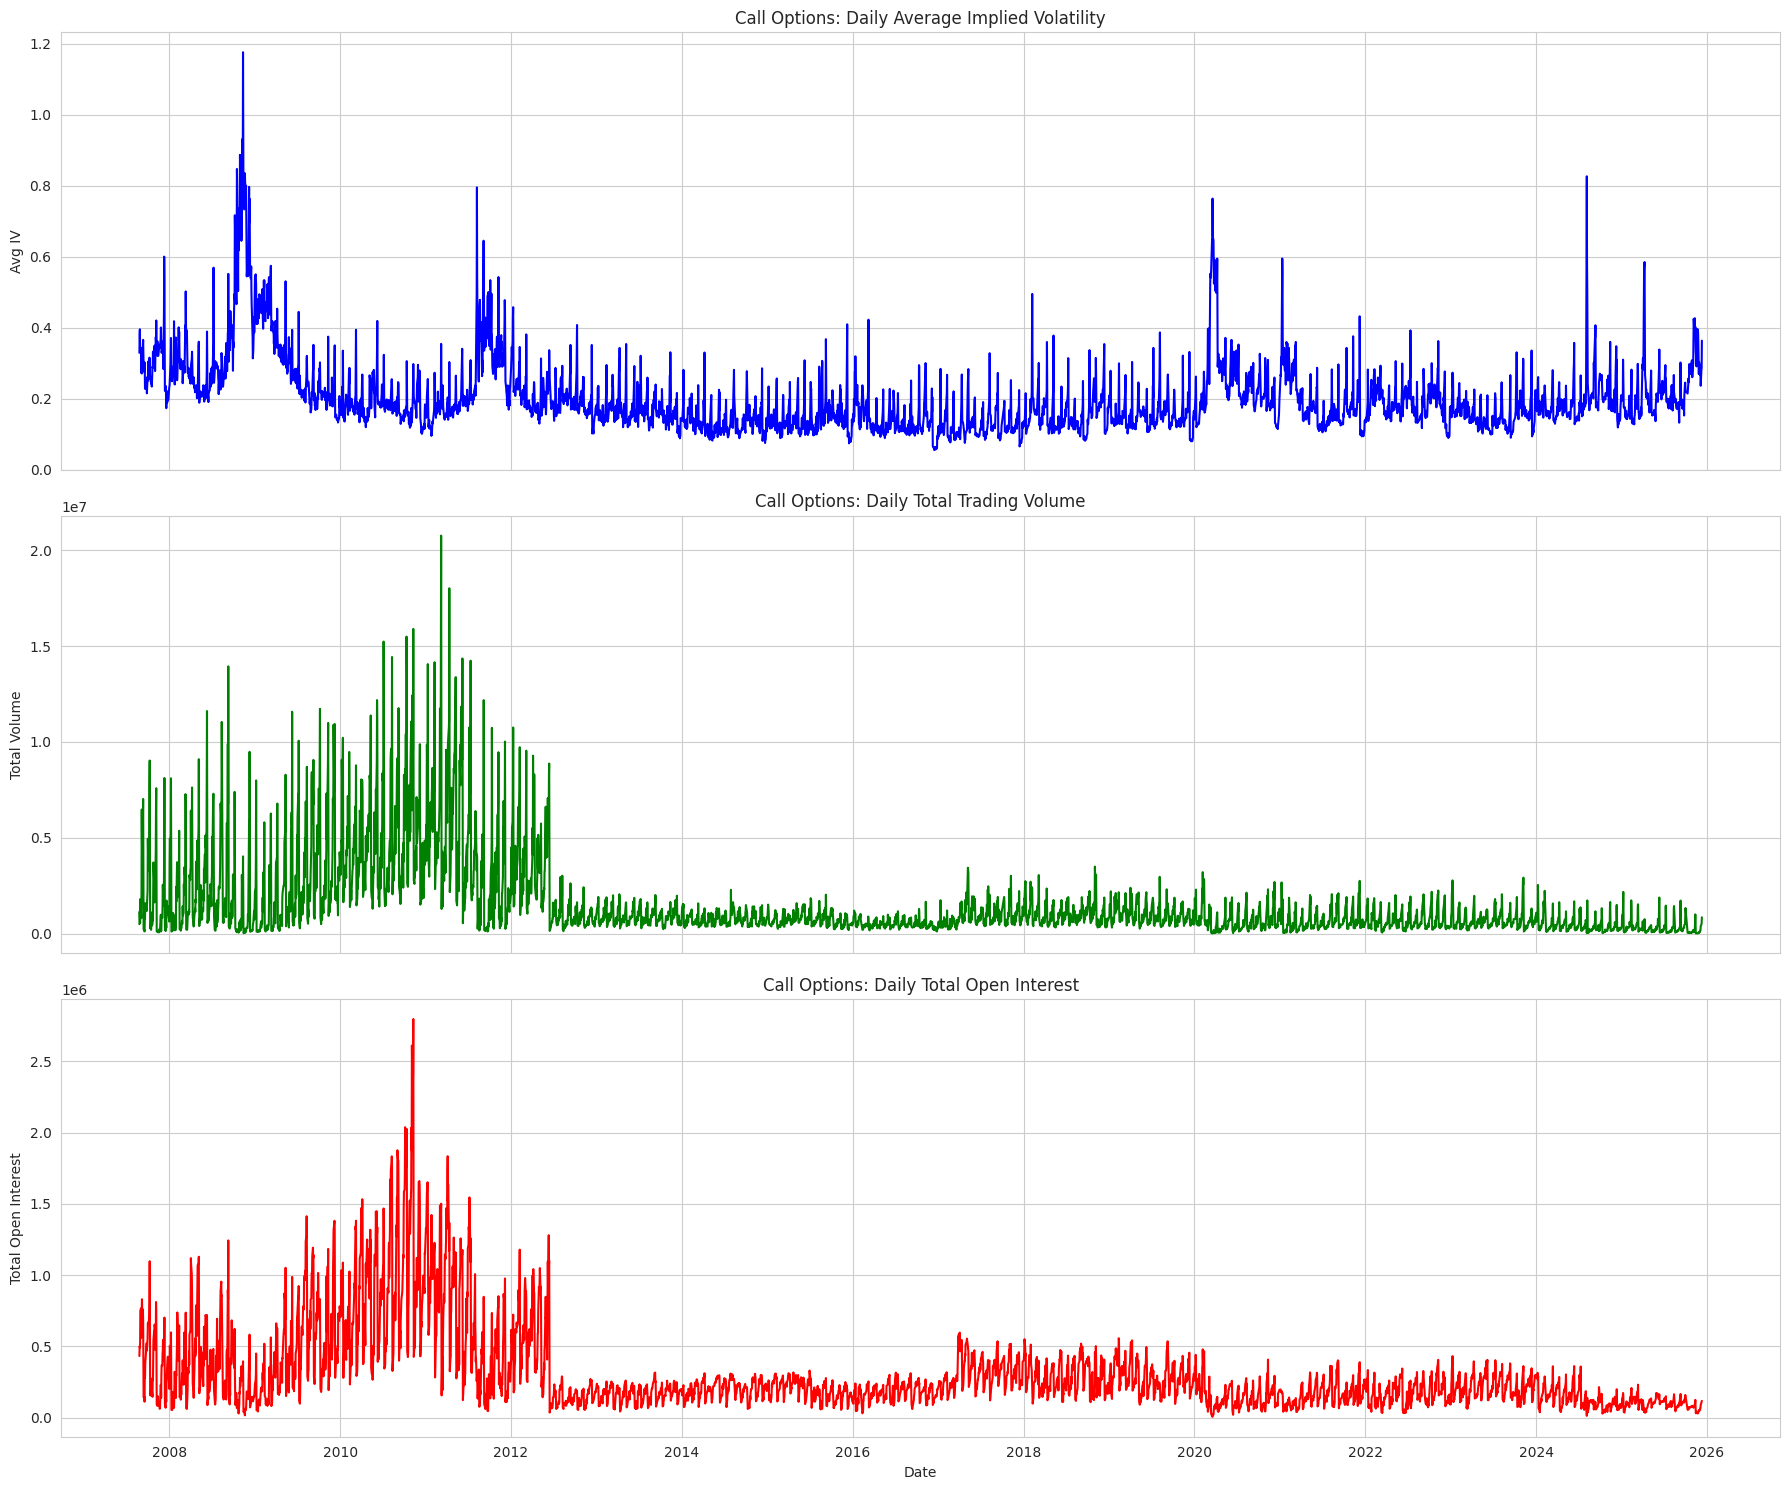

콜 옵션 내재변동성, 거래량, 미결제약정 시계열 그래프가 생성되었습니다.


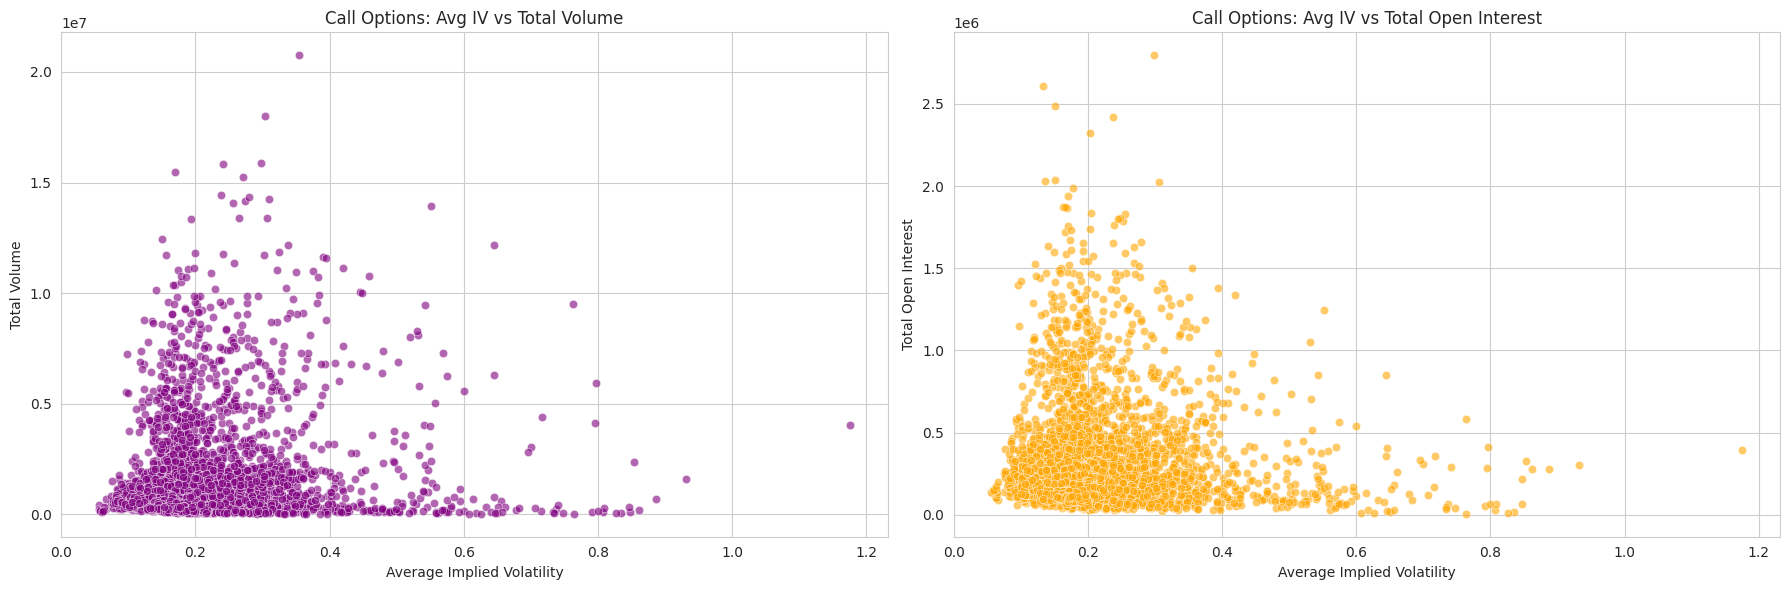

콜 옵션 내재변동성과 거래량/미결제약정 산점도 그래프가 생성되었습니다.

### 풋 옵션: 내재변동성, 거래량, 미결제약정 관계 분석 ###

풋 옵션 일별 요약 통계량:


,Avg_IV,Total_Volume,Total_Open_Interest
count,4292.000000,4.292000e+03,4.292000e+03
mean,0.217849,1.159340e+06,2.403655e+05
std,0.105982,1.755902e+06,2.116751e+05
min,0.091009,8.375000e+03,1.235300e+04
25%,0.151951,2.982705e+05,1.103845e+05
50%,0.191984,5.562620e+05,1.771060e+05
75%,0.247721,1.175441e+06,2.830192e+05
max,1.118205,1.765411e+07,1.613772e+06



풋 옵션 상관관계 (IV, 거래량, 미결제약정):


,Avg_IV,Total_Volume,Total_Open_Interest
Avg_IV,1.000000,0.179073,0.141931
Total_Volume,0.179073,1.000000,0.882245
Total_Open_Interest,0.141931,0.882245,1.000000


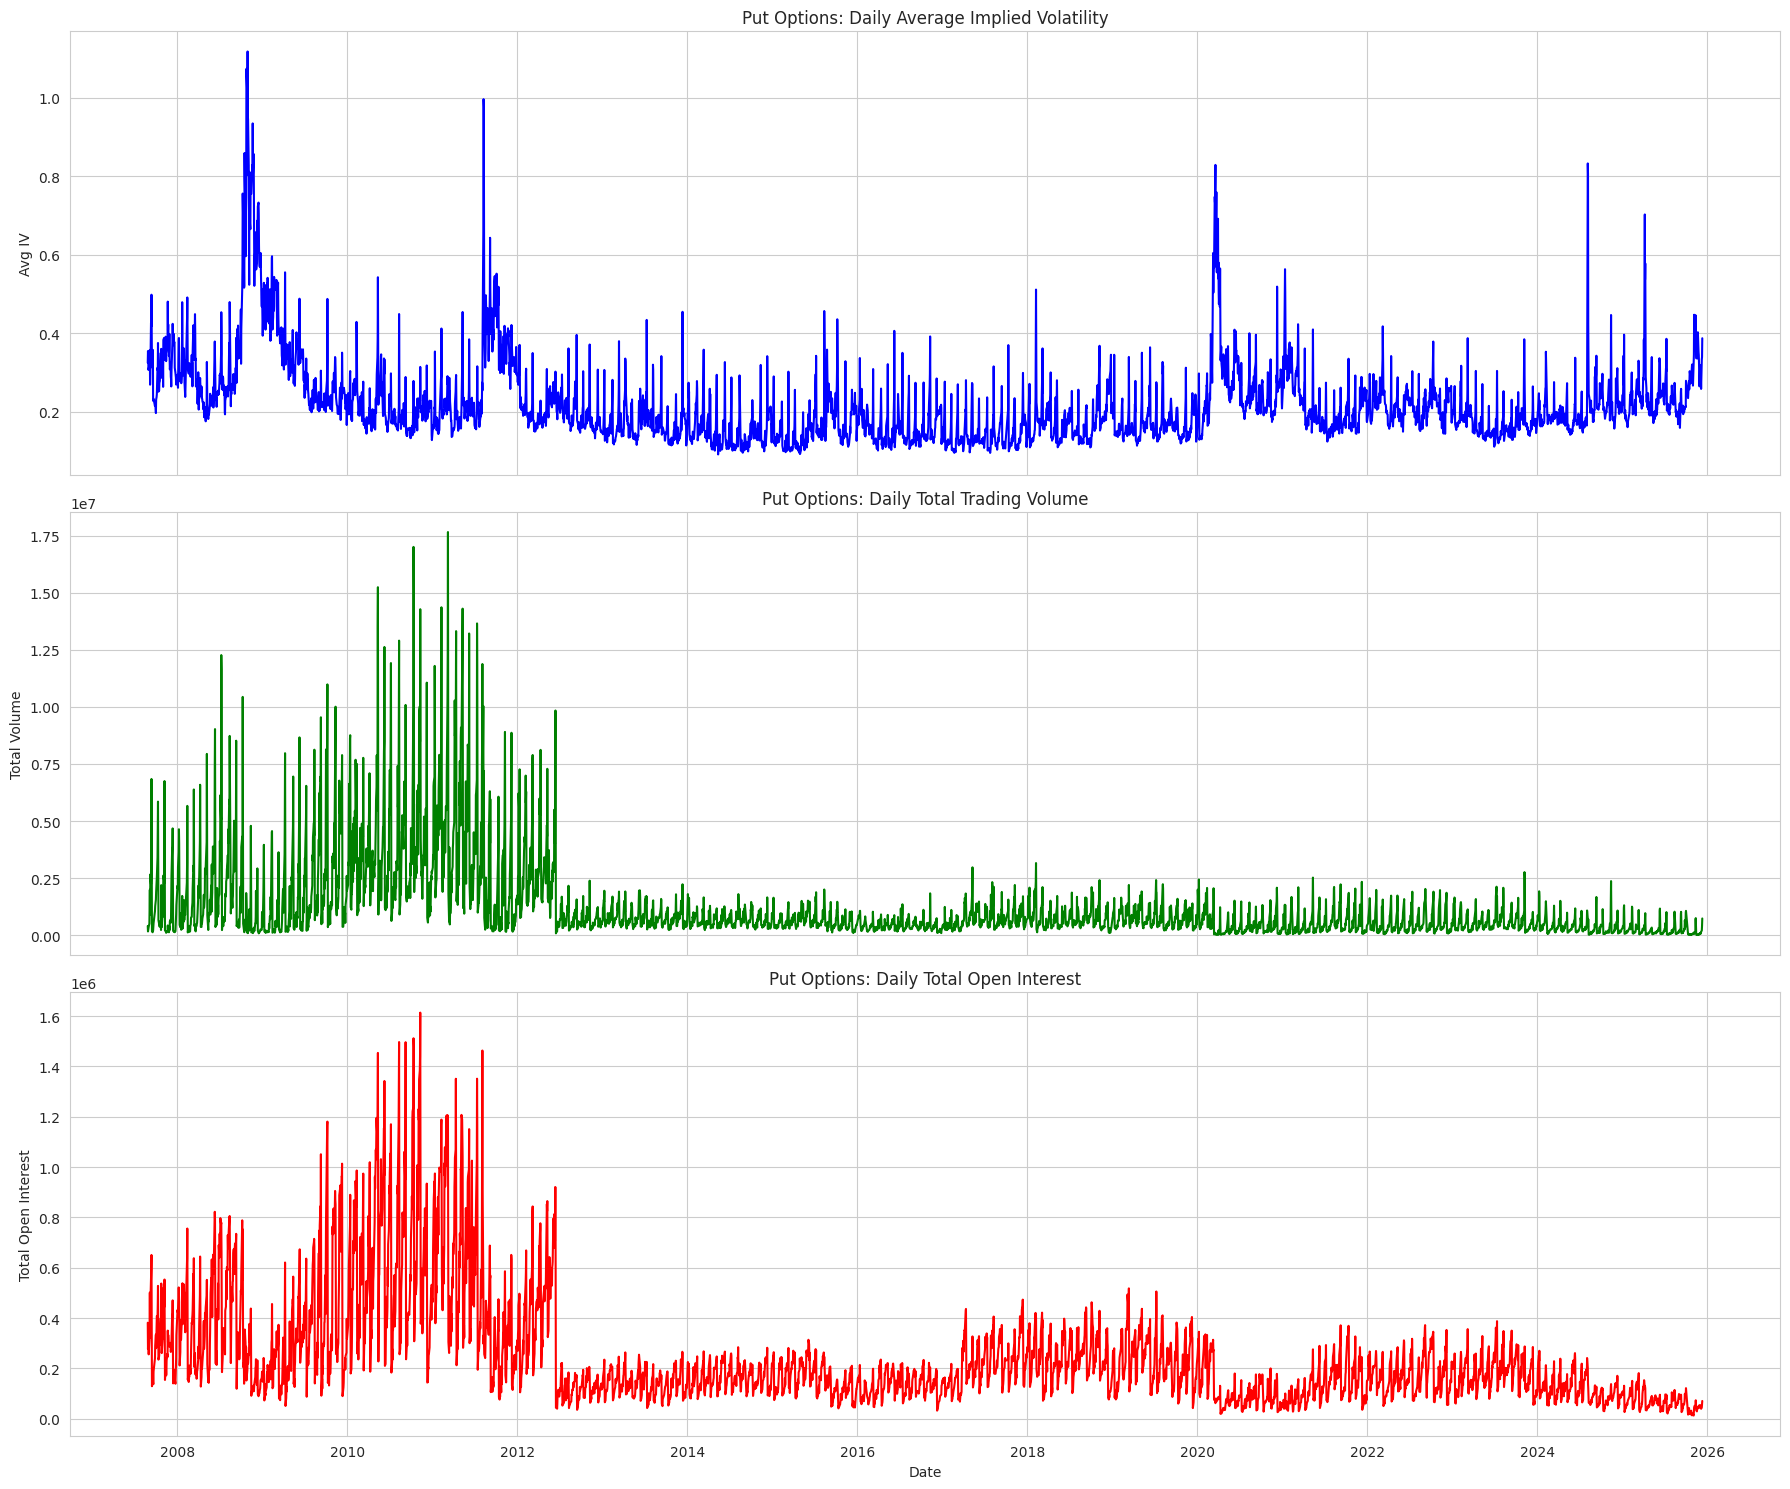

풋 옵션 내재변동성, 거래량, 미결제약정 시계열 그래프가 생성되었습니다.


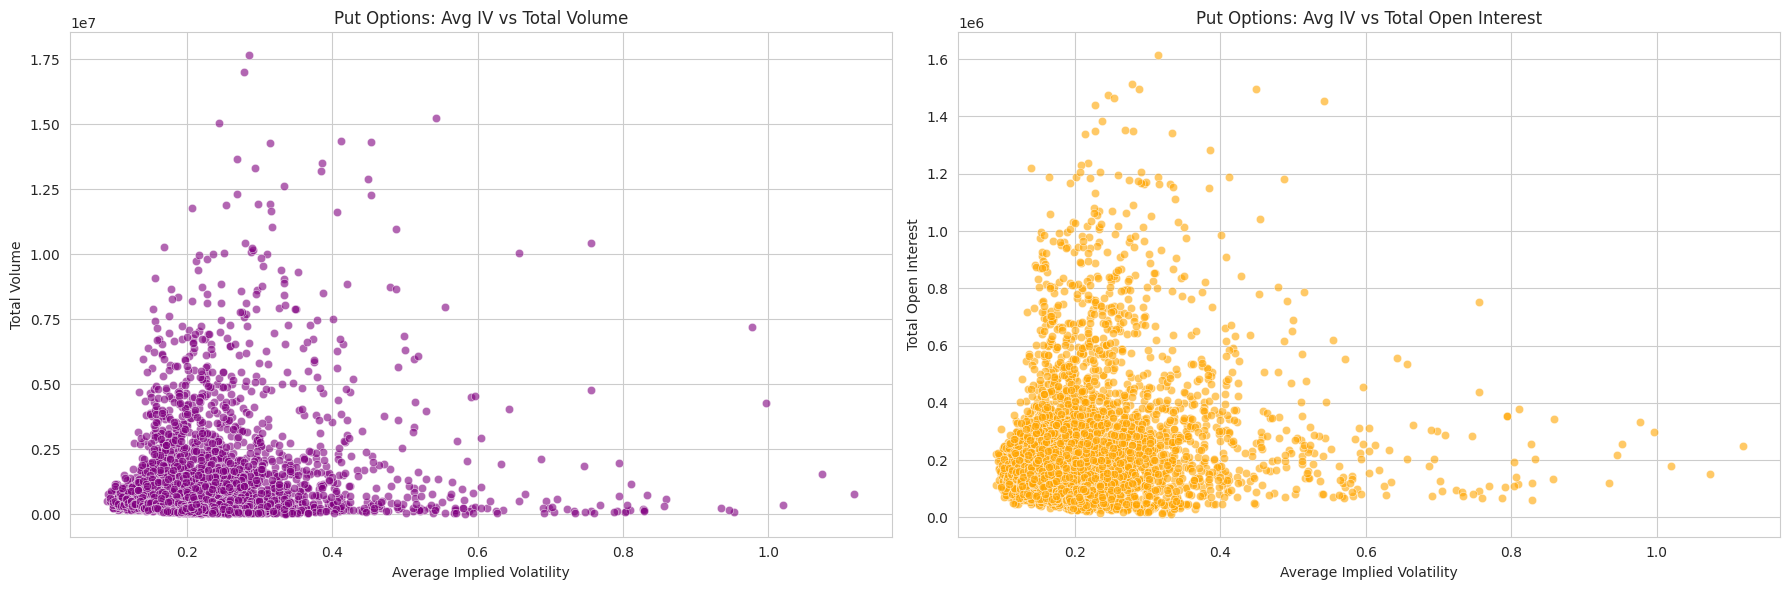

풋 옵션 내재변동성과 거래량/미결제약정 산점도 그래프가 생성되었습니다.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. 콜 옵션 분석: 내재변동성, 거래량, 미결제약정 관계 --- #
print("### 콜 옵션: 내재변동성, 거래량, 미결제약정 관계 분석 ###")

if 'atm_calls' not in locals() or atm_calls.empty:
    print("경고: 'atm_calls'이(가) 정의되지 않았거나 비어있습니다. 이전 셀을 실행하여 해당 변수를 생성해주세요.")
    call_data_daily = pd.DataFrame({
        '일자_datetime': pd.to_datetime(['2023-01-01', '2023-01-02', '2023-01-03']),
        'Avg_IV': [0.2, 0.22, 0.21],
        'Total_Volume': [1000, 1200, 1100],
        'Total_Open_Interest': [5000, 5100, 4900]
    })
else:
    # 일별 평균 IV, 총 거래량, 총 미결제약정 집계
    call_data_daily = atm_calls.groupby('일자_datetime').agg(
        Avg_IV=('Implied_Volatility', 'mean'),
        Total_Volume=('거래량', 'sum'),
        Total_Open_Interest=('미결제약정', 'sum')
    ).sort_index()
    # NaN 값 제거 (집계 후에도 존재할 수 있는 경우)
    call_data_daily.dropna(inplace=True)


if not call_data_daily.empty:
    print("\n콜 옵션 일별 요약 통계량:")
    display(call_data_daily.describe())

    # 상관관계 계산
    print("\n콜 옵션 상관관계 (IV, 거래량, 미결제약정):")
    display(call_data_daily[['Avg_IV', 'Total_Volume', 'Total_Open_Interest']].corr())

    # 시계열 플롯
    fig, axes = plt.subplots(3, 1, figsize=(18, 15), sharex=True)
    sns.lineplot(ax=axes[0], x=call_data_daily.index, y='Avg_IV', data=call_data_daily, color='blue')
    axes[0].set_title('Call Options: Daily Average Implied Volatility')
    axes[0].set_ylabel('Avg IV')
    axes[0].grid(True)

    sns.lineplot(ax=axes[1], x=call_data_daily.index, y='Total_Volume', data=call_data_daily, color='green')
    axes[1].set_title('Call Options: Daily Total Trading Volume')
    axes[1].set_ylabel('Total Volume')
    axes[1].grid(True)

    sns.lineplot(ax=axes[2], x=call_data_daily.index, y='Total_Open_Interest', data=call_data_daily, color='red')
    axes[2].set_title('Call Options: Daily Total Open Interest')
    axes[2].set_ylabel('Total Open Interest')
    axes[2].set_xlabel('Date')
    axes[2].grid(True)

    plt.tight_layout()
    plt.show()
    print("콜 옵션 내재변동성, 거래량, 미결제약정 시계열 그래프가 생성되었습니다.")

    # 산점도
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    sns.scatterplot(ax=axes[0], x='Avg_IV', y='Total_Volume', data=call_data_daily, alpha=0.6, color='purple')
    axes[0].set_title('Call Options: Avg IV vs Total Volume')
    axes[0].set_xlabel('Average Implied Volatility')
    axes[0].set_ylabel('Total Volume')
    axes[0].grid(True)

    sns.scatterplot(ax=axes[1], x='Avg_IV', y='Total_Open_Interest', data=call_data_daily, alpha=0.6, color='orange')
    axes[1].set_title('Call Options: Avg IV vs Total Open Interest')
    axes[1].set_xlabel('Average Implied Volatility')
    axes[1].set_ylabel('Total Open Interest')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()
    print("콜 옵션 내재변동성과 거래량/미결제약정 산점도 그래프가 생성되었습니다.")

else:
    print("콜 옵션 데이터가 충분하지 않아 분석을 수행할 수 없습니다.")


# --- 2. 풋 옵션 분석: 내재변동성, 거래량, 미결제약정 관계 --- #
print("\n### 풋 옵션: 내재변동성, 거래량, 미결제약정 관계 분석 ###")

if 'atm_puts' not in locals() or atm_puts.empty:
    print("경고: 'atm_puts'이(가) 정의되지 않았거나 비어있습니다. 이전 셀을 실행하여 해당 변수를 생성해주세요.")
    put_data_daily = pd.DataFrame({
        '일자_datetime': pd.to_datetime(['2023-01-01', '2023-01-02', '2023-01-03']),
        'Avg_IV': [0.25, 0.23, 0.24],
        'Total_Volume': [800, 900, 850],
        'Total_Open_Interest': [4000, 4200, 4100]
    })
else:
    # 일별 평균 IV, 총 거래량, 총 미결제약정 집계
    put_data_daily = atm_puts.groupby('일자_datetime').agg(
        Avg_IV=('Implied_Volatility', 'mean'),
        Total_Volume=('거래량', 'sum'),
        Total_Open_Interest=('미결제약정', 'sum')
    ).sort_index()
    # NaN 값 제거
    put_data_daily.dropna(inplace=True)


if not put_data_daily.empty:
    print("\n풋 옵션 일별 요약 통계량:")
    display(put_data_daily.describe())

    # 상관관계 계산
    print("\n풋 옵션 상관관계 (IV, 거래량, 미결제약정):")
    display(put_data_daily[['Avg_IV', 'Total_Volume', 'Total_Open_Interest']].corr())

    # 시계열 플롯
    fig, axes = plt.subplots(3, 1, figsize=(18, 15), sharex=True)
    sns.lineplot(ax=axes[0], x=put_data_daily.index, y='Avg_IV', data=put_data_daily, color='blue')
    axes[0].set_title('Put Options: Daily Average Implied Volatility')
    axes[0].set_ylabel('Avg IV')
    axes[0].grid(True)

    sns.lineplot(ax=axes[1], x=put_data_daily.index, y='Total_Volume', data=put_data_daily, color='green')
    axes[1].set_title('Put Options: Daily Total Trading Volume')
    axes[1].set_ylabel('Total Volume')
    axes[1].grid(True)

    sns.lineplot(ax=axes[2], x=put_data_daily.index, y='Total_Open_Interest', data=put_data_daily, color='red')
    axes[2].set_title('Put Options: Daily Total Open Interest')
    axes[2].set_ylabel('Total Open Interest')
    axes[2].set_xlabel('Date')
    axes[2].grid(True)

    plt.tight_layout()
    plt.show()
    print("풋 옵션 내재변동성, 거래량, 미결제약정 시계열 그래프가 생성되었습니다.")

    # 산점도
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    sns.scatterplot(ax=axes[0], x='Avg_IV', y='Total_Volume', data=put_data_daily, alpha=0.6, color='purple')
    axes[0].set_title('Put Options: Avg IV vs Total Volume')
    axes[0].set_xlabel('Average Implied Volatility')
    axes[0].set_ylabel('Total Volume')
    axes[0].grid(True)

    sns.scatterplot(ax=axes[1], x='Avg_IV', y='Total_Open_Interest', data=put_data_daily, alpha=0.6, color='orange')
    axes[1].set_title('Put Options: Avg IV vs Total Open Interest')
    axes[1].set_xlabel('Average Implied Volatility')
    axes[1].set_ylabel('Total Open Interest')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()
    print("풋 옵션 내재변동성과 거래량/미결제약정 산점도 그래프가 생성되었습니다.")

else:
    print("풋 옵션 데이터가 충분하지 않아 분석을 수행할 수 없습니다.")

위에서 계산한 내재변동성과 원데이터에 있는 내재변동성,
시계열 그래프

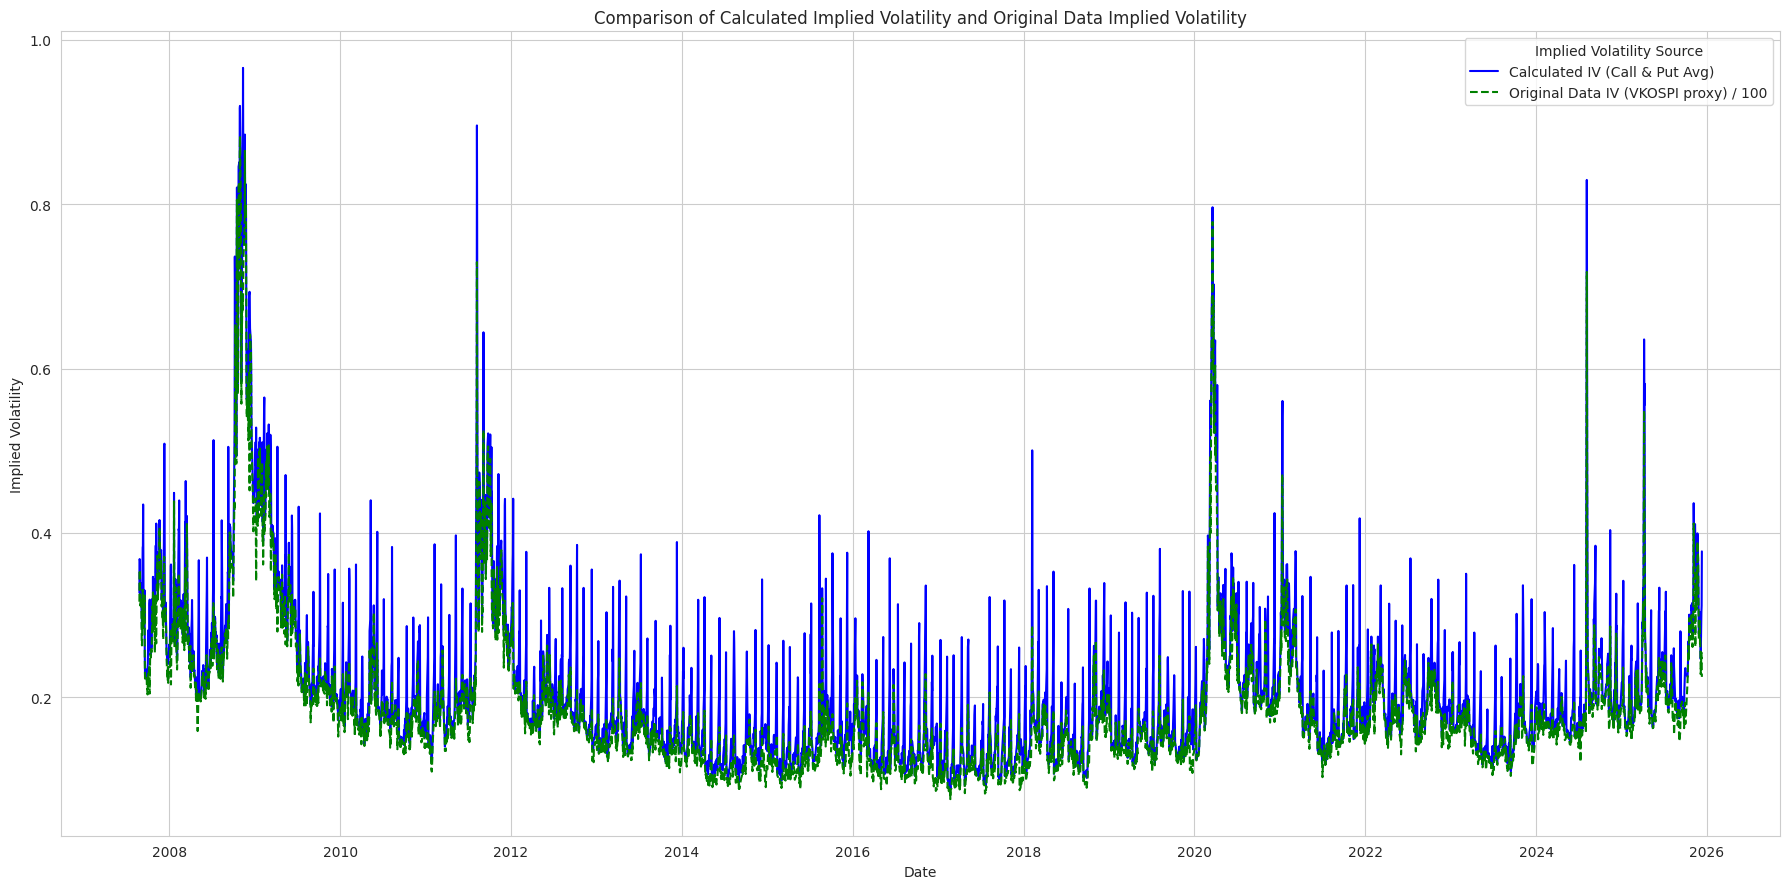

계산된 내재변동성과 원본 데이터의 내재변동성 시계열 비교 그래프가 생성되었습니다.

### 계산된 IV와 스케일링된 원본 IV 간의 차이 통계량 ###


,IV_Difference_Scaled
count,4292.000000
mean,0.023134
std,0.033136
min,-0.003904
25%,0.005582
50%,0.010653
75%,0.023656
max,0.284061



### 계산된 IV와 스케일링된 원본 IV 간의 상관관계 ###
Correlation between Calculated IV and Scaled Original Data IV: 0.9467


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# daily_straddle_summary는 이전 셀에서 생성되었으며
# 'Avg_Calculated_Straddle_IV' (계산된 IV 평균)과 'Avg_Original_IV' (원본 데이터 IV/VKOSPI 대용치)를 포함합니다.
if 'daily_straddle_summary' not in locals() or daily_straddle_summary.empty:
    print("경고: 'daily_straddle_summary'가(이) 정의되지 않았거나 비어있습니다. 이전 셀을 실행하여 daily_straddle_summary를 먼저 생성해주세요.")
    # 임시 데이터 생성 (실제 환경에서는 이전 셀에서 로드된 daily_straddle_summary 사용)
    daily_straddle_summary = pd.DataFrame({
        'Avg_Calculated_Straddle_IV': [0.2, 0.22, 0.21, 0.23, 0.24],
        'Avg_Original_IV': [0.21, 0.23, 0.22, 0.24, 0.25]
    }, index=pd.to_datetime(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04', '2023-01-05']))

if not daily_straddle_summary.empty:
    plt.figure(figsize=(18, 9))
    sns.set_style("whitegrid")

    # 'Avg_Calculated_Straddle_IV' (계산된 내재변동성)
    sns.lineplot(x=daily_straddle_summary.index, y='Avg_Calculated_Straddle_IV', data=daily_straddle_summary, label='Calculated IV (Call & Put Avg)', color='blue')

    # 'Avg_Original_IV' (원본 데이터 내재변동성)
    # 원본 IV가 백분율로 되어있을 수 있으므로 100으로 나누어 스케일 조정 (선택적)
    # 만약 Avg_Original_IV가 이미 소수점 형태라면 이 라인은 주석 처리하거나 제거하세요.
    # 여기서는 이전 분석에서 Original_IV가 percentage 스케일이었음이 확인되었으므로 100으로 나눕니다.
    sns.lineplot(x=daily_straddle_summary.index, y=daily_straddle_summary['Avg_Original_IV'] / 100.0, label='Original Data IV (VKOSPI proxy) / 100', color='green', linestyle='--')

    plt.title('Comparison of Calculated Implied Volatility and Original Data Implied Volatility')
    plt.xlabel('Date')
    plt.ylabel('Implied Volatility')
    plt.legend(title='Implied Volatility Source')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print("계산된 내재변동성과 원본 데이터의 내재변동성 시계열 비교 그래프가 생성되었습니다.")

    # 추가 분석: 두 IV 간의 차이 통계량
    # 원본 IV가 스케일링된 경우를 대비하여 다시 계산하거나 스케일링된 값으로 비교
    daily_straddle_summary['IV_Difference_Scaled'] = daily_straddle_summary['Avg_Calculated_Straddle_IV'] - (daily_straddle_summary['Avg_Original_IV'] / 100.0)
    print("\n### 계산된 IV와 스케일링된 원본 IV 간의 차이 통계량 ###")
    display(daily_straddle_summary['IV_Difference_Scaled'].describe())

    # 추가 분석: 두 IV 간의 상관관계 (스케일링된 값으로)
    print("\n### 계산된 IV와 스케일링된 원본 IV 간의 상관관계 ###")
    correlation_scaled = daily_straddle_summary['Avg_Calculated_Straddle_IV'].corr(daily_straddle_summary['Avg_Original_IV'] / 100.0)
    print(f"Correlation between Calculated IV and Scaled Original Data IV: {correlation_scaled:.4f}")

else:
    print("그래프를 그릴 데이터가 충분하지 않습니다.")